We implement a Bayesian Varying Coefficient Model (BVCM) to analyze and generate realistic human skin reflectance spectra based on the ISSA dataset.

**Key Features:**

- Models skin reflectance as a function of melanin index and erythema index
- Uses Gaussian Processes for smooth, wavelength-dependent coefficient functions
- Captures subject-specific variations through random effect GPs
- Enables synthetic spectra generation with biologically plausible characteristics
- Provides a two-stage validation filter for quality control of simra Validation Filter

# Model specification

## Mathematical formulation

Assume we have skin reflectance spectra $Y_i(\lambda) \in [0,1]$ for individuals $i = 1, \ldots, N$ measured at wavelengths $\lambda \in [400, 700]$ nm. We apply a logit transformation on the skin reflectance to ensure the transformed values are in the range $(-\infty, \infty)$. The BVCM can be formulated as:
$$logit(Y_i(\lambda)) = \beta_0(\lambda) + X_{MI,i} \beta_{MI}(\lambda) + X_{EI,i} \beta_{EI}(\lambda) + Z_i(\lambda) + \epsilon_i(\lambda),$$
where $\beta_0(\lambda)$ is the intercept function, $\beta_{MI}(\lambda)$ and $\beta_{EI}(\lambda)$ are the varying coefficient functions for melanin and erythema variables, respectively. $Z_i(\lambda)$ represents subject-specific deviations modeled as a Gaussian process, and $\epsilon_i(\lambda)$ is the measurement error.

The melanin and hemoglobin variables are calculated as:

- **Melanin index**: $$X_{MI,i} = 100 \times \log_{10}\left(\frac{1}{R_{680,i}}\right),$$ where $R_{680,i}$ is reflectance at 680nm for individual $i$.
- **Erythema index**: $$X_{EI,i} = 100 \times \log_{10}\left(\frac{R_{680,i}}{R_{560,i}}\right).$$

## Spline basis representation and Hilbert space GP priors

We represent the intercept and coefficient functions using cubic P-spline basis functions. Each function is expressed as:
$$\beta_k(\lambda) = \sum_{j=1}^{J} b_{k,j} B_j(\lambda),$$
where $B_j(\lambda)$ are the spline basis functions and $b_{k,j}$ are the coefficients. Here we set $J=20$.

We employ the Hilbert Space Gaussian Process (HSGP) approximation to model the random effect functions $Z_i(\lambda)$, allowing efficient computation while capturing smooth variations. We approximate the GP $Z(\lambda)$ using a finite set of basis functions derived from the eigenfunctions of the covariance kernel:
$$Z(\lambda) \approx \sum_{m=1}^{M} w_m \phi_m(\lambda),$$
where $\phi_m(\lambda)$ are the basis functions and $w_m$ are the weights drawn from a Gaussian distribution. For a stationary kernel (like Matern) in 1D, the basis functions are sine waves determined by the domain size, and the variance of the weights is determined by the Spectral Density of the kernel. Specifically,
$$Z(\lambda) \approx \sum_{m=1}^M \frac{1}{\sqrt{L}} \sin \left(\frac{m\pi(\lambda+L)}{2L}\right) \cdot \sqrt{S(\omega_m)} \cdot w_m,$$
where $L$ is half the domain length, $S(\omega_m)$ is the spectral density at frequency $\omega_m = \frac{m\pi}{2L}$, and $w_m \sim \mathcal{N}(0,1)$. Here we set $M=10$.

## Prior specifications

We define the following prior distributions for the model parameters:

- Random walk priors for spline coefficients:
  - $$\Delta^2 b_{k,j} = b_{k,j} - 2b_{k,j-1} + b_{k,j-2} \sim N(0, \tau_{\beta}^2),$$
    where $\tau_{\beta}=1$ controls the smoothness of the coefficient functions.
- Gaussian Process prior for subject-specific deviations:
  - $$Z_i(\lambda) \sim GP(0, K_{Z}(\lambda, \lambda')),$$
    where $K_{Z}(\lambda, \lambda')$ is a Matern52 covariance function with length $\rho_{Z}$ and scale $\sigma_{Z}$.
  - $$\rho_{Z} \sim Gamma(50, 1), \quad \sigma_{Z} \sim HalfNormal(0.5).$$
- Normal prior for measurement error:
  - $$\epsilon_i(\lambda) \sim N(0, \sigma_{\epsilon}^2),$$
    where $\sigma_{\epsilon}^2$ is the variance of the measurement error.
  - $$\sigma_{\epsilon}^2 \sim IG(1, 1).$$

In [1]:
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# set random seed for reproducibility
np.random.seed(123)

import warnings
warnings.filterwarnings('ignore')

# Support execution from the project root or its notebooks directory.
project_root = Path.cwd().resolve()
if project_root.name == 'notebooks':
    project_root = project_root.parent
if not (project_root / 'notebooks' / 'bvcm.ipynb').is_file():
    raise FileNotFoundError('Run from SkinSim_Quarto or SkinSim_Quarto/notebooks.')
os.chdir(project_root / 'notebooks')
script_dir = str(project_root / 'code')

# Add it to the system path
if script_dir not in sys.path:
    sys.path.append(script_dir)


In [2]:
# Load data
# Get the data directory located one level up from the current working directory
data_dir = project_root / 'data'
issa_path = Path(os.environ.get('ISSA_DATA_PATH', str(data_dir / 'ISSA_17_Jan_2025_Yan_Lu.xlsx')))
if not issa_path.is_file():
    raise FileNotFoundError(f'ISSA workbook is missing: {issa_path}. Place it in data/ or set ISSA_DATA_PATH.')

# Load the real issa spectra data from CSV files
issa_data = pd.read_excel(issa_path, sheet_name='ISSA')
site_names = {1: 'Back of Hand', 2: 'Cheek', 3: 'Cheek Bone', 4: 'Chin', 5: 'Ear lobe', 6: 'Forehead', 
              7: 'Inner arm', 8: 'Neck', 9: 'Nose tip', 10: 'Outer arm', 11: 'Palm', 12: 'Ring finger'}
issa_wavelengths = issa_data.iloc[10, 17:48].values.astype(float)
issa_sites = issa_data.iloc[11:, 6].values.astype(int)
issa_spectra = issa_data.iloc[11:, 17:48].to_numpy()

# Filter the issa spectra to include only face sites
face_spectra = issa_spectra[np.isin(issa_sites, [2, 3, 4, 5, 6, 9]), :]
face_sites = issa_sites[np.isin(issa_sites, [2, 3, 4, 5, 6, 9])]

# calculate the first derivative of the spectra
from scipy.signal import savgol_filter
face_drv = savgol_filter(face_spectra, window_length=5, polyorder=3, axis=1, deriv=1) / np.gradient(issa_wavelengths)  # First derivative with respect to wavelength

# remove outliers based on the first derivative
face_drv_mean = np.mean(face_drv, axis=0)
face_drv_std = np.std(face_drv, axis=0)
outlier_mask = np.any(np.abs(face_drv - face_drv_mean) > 5 * face_drv_std, axis=1)
face_spectra_clean = face_spectra[~outlier_mask, :]
face_sites_clean = face_sites[~outlier_mask]
face_drv_clean = face_drv[~outlier_mask, :]

# Calculate the melanin and erythema index
face_mi = 100 * np.log10(100 / face_spectra_clean[:, 28]) # 680 nm
# face_red = (face_spectra_clean[:, 14] + face_spectra_clean[:, 16] + face_spectra_clean[:, 18]) / 3  # Average of 540 nm, 560 nm, and 580 nm
face_ei = 100 * np.log10(face_spectra_clean[:, 28] / face_spectra_clean[:, 16]) # 680 nm / 560 nm

In [3]:
# Calculate the covariate matrix X
X = np.column_stack((np.ones(face_spectra_clean.shape[0]), face_mi, face_ei))  # Shape: (N, 3)
# Split data into training and testing sets
N = face_spectra_clean.shape[0]
train_indices = np.random.choice(N, size=int(0.8 * N), replace=False)
test_indices = np.setdiff1d(np.arange(N), train_indices)
train_spectra = face_spectra_clean[train_indices, :]
test_spectra = face_spectra_clean[test_indices, :]
train_X = X[train_indices, :]
test_X = X[test_indices, :]

# Exploratory analysis on ISSA face sites

## Skin reflectance and its first derivative

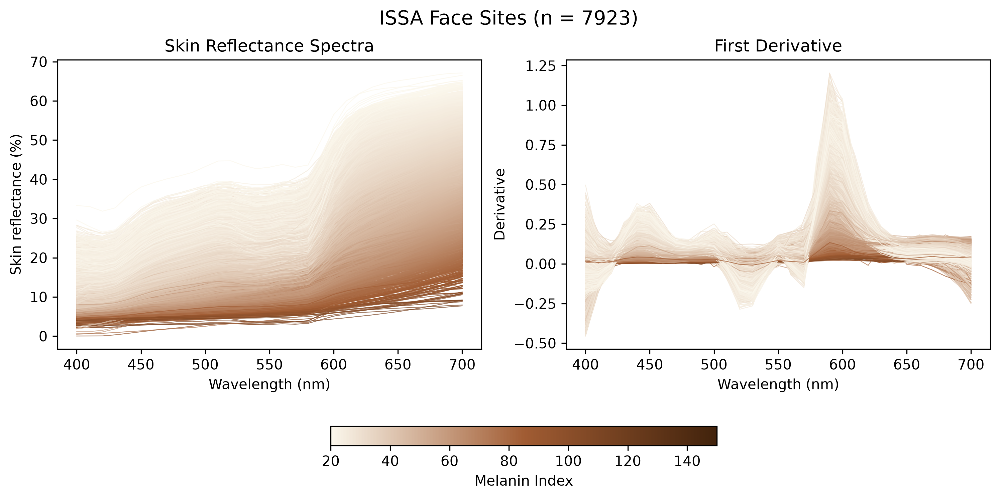

In [4]:
# Visualize the skin reflectance spectra and melanin vs erythema index side by side
fitzpatrick = ["#fbf7ec", "#a15c33", "#42230c"]
cmap = LinearSegmentedColormap.from_list("fitzpatrick", fitzpatrick)
norm = plt.Normalize(vmin=20, vmax=150)
face_mi_clipped = np.clip(face_mi, 20, 150)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=300)

# Plot ISSA spectra
ax = axes[0]
for i in range(face_spectra_clean.shape[0]):
    color = cmap(norm(face_mi_clipped[i]))
    ax.plot(issa_wavelengths, face_spectra_clean[i, :], color=color, alpha=0.7, linewidth=0.6)
ax.set_title('Skin Reflectance Spectra')
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('Skin reflectance (%)')

# Plot ISSA derivative
ax = axes[1]
for i in range(face_drv_clean.shape[0]):
    color = cmap(norm(face_mi_clipped[i]))
    ax.plot(issa_wavelengths, face_drv_clean[i, :], color=color, alpha=0.7, linewidth=0.6)
ax.set_title('First Derivative')
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('Derivative')

# -------- Colorbar --------
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=axes,
    orientation="horizontal",
    fraction=0.05,     # thickness
    pad=0.2            # distance from plots
)
cbar.set_label("Melanin Index")

# ---- Common title ----
fig.suptitle(f'ISSA Face Sites (n = {face_spectra_clean.shape[0]})', fontsize=14)
# plt.tight_layout()
plt.show()

## Eumelanin human skin colour scale

ISSA Face Sites Eumelanin Class Summary Table:

In [5]:
# Set up the exact boundaries for the Eumelanin classes
# We use right=False in pd.cut so the bins are [lower, upper)
em_bins = [-np.inf, 25, 50, 75, 100, np.inf]
em_labels = ['EML (<25)', 'EMIL (25-49)', 'EMI (50-74)', 'EMIH (75-99)', 'EMH (>=100)']

face_df = pd.DataFrame({
    'Site_ID': face_sites_clean,
    'Site': [site_names[site] for site in face_sites_clean],
    'MI': face_mi,
    'EI': face_ei
})

# Sort the MI values into their new categories
face_df['Eumelanin Class'] = pd.cut(face_df['MI'], bins=em_bins, labels=em_labels, right=False)

# Build the final frequency table
face_summary_table = pd.crosstab(face_df['Site'], face_df['Eumelanin Class'])
face_summary_table.loc['Total'] = face_summary_table.sum()

# Display the result
# print("ISSA Face Sites Eumelanin Class Summary Table:")
face_summary_table

Eumelanin Class,EML (<25),EMIL (25-49),EMI (50-74),EMIH (75-99),EMH (>=100)
Site,,,,,
Cheek,216,1978,227,50,4
Cheek Bone,24,186,18,0,0
Chin,271,1507,211,36,5
Ear lobe,9,394,57,12,3
Forehead,77,1772,190,30,3
Nose tip,29,582,31,1,0
Total,626,6419,734,129,15


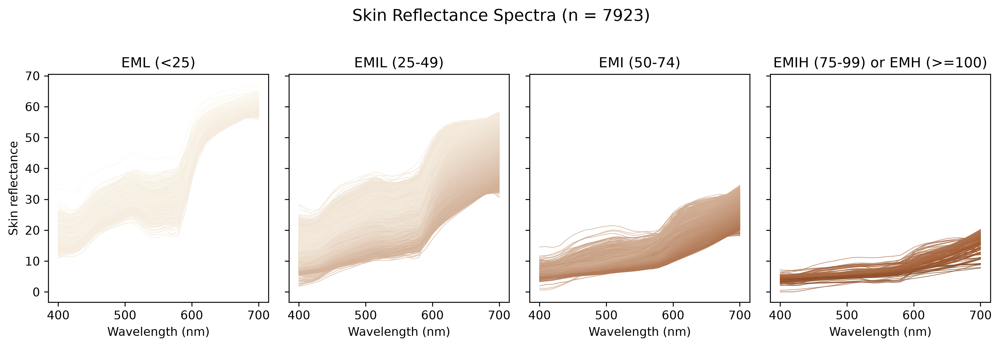

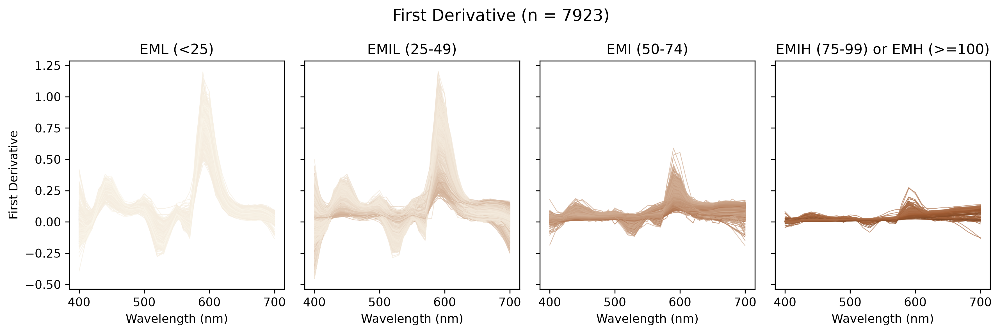

In [6]:
# Visualize the skin reflectance spectra and melanin vs erythema index side by side
fitzpatrick = ["#fbf7ec", "#a15c33", "#42230c"]
cmap = LinearSegmentedColormap.from_list("fitzpatrick", fitzpatrick)
norm = plt.Normalize(vmin=20, vmax=150)
face_mi_clipped = np.clip(face_mi, 20, 150)

fig, axes = plt.subplots(1, 4, figsize=(12, 4), dpi=300, sharey=True)

# Plot ISSA spectra
ax = axes[0]
eml_mask = (face_df['Eumelanin Class'] == 'EML (<25)')
eml_indices = face_df[eml_mask].index
for i in eml_indices:
    color = cmap(norm(face_mi_clipped[i]))
    ax.plot(issa_wavelengths, face_spectra_clean[i, :], color=color, alpha=0.7, linewidth=0.6)
ax.set_title('EML (<25)')
ax.set_ylabel('Skin reflectance')
ax.set_xlabel('Wavelength (nm)')

# Plot ISSA spectra
ax = axes[1]
emil_mask = (face_df['Eumelanin Class'] == 'EMIL (25-49)')
emil_indices = face_df[emil_mask].index
for i in emil_indices:
    color = cmap(norm(face_mi_clipped[i]))
    ax.plot(issa_wavelengths, face_spectra_clean[i, :], color=color, alpha=0.7, linewidth=0.6)
ax.set_title('EMIL (25-49)')
ax.set_xlabel('Wavelength (nm)')

# Plot ISSA spectra
ax = axes[2]
emi_mask = (face_df['Eumelanin Class'] == 'EMI (50-74)')
emi_indices = face_df[emi_mask].index
for i in emi_indices:
    color = cmap(norm(face_mi_clipped[i]))
    ax.plot(issa_wavelengths, face_spectra_clean[i, :], color=color, alpha=0.7, linewidth=0.6)
ax.set_title('EMI (50-74)')
ax.set_xlabel('Wavelength (nm)')

# Plot ISSA spectra
ax = axes[3]
emh_mask = (face_df['Eumelanin Class'] == 'EMIH (75-99)') | (face_df['Eumelanin Class'] == 'EMH (>=100)')
emh_indices = face_df[emh_mask].index
for i in emh_indices:
    color = cmap(norm(face_mi_clipped[i]))
    ax.plot(issa_wavelengths, face_spectra_clean[i, :], color=color, alpha=0.7, linewidth=0.6)
ax.set_title('EMIH (75-99) or EMH (>=100)')
ax.set_xlabel('Wavelength (nm)')

plt.suptitle(f'Skin Reflectance Spectra (n = {face_spectra_clean.shape[0]})', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


fig, axes = plt.subplots(1, 4, figsize=(12, 4), dpi=300, sharey=True)

# Plot ISSA derivative
ax = axes[0]
for i in eml_indices:
    color = cmap(norm(face_mi_clipped[i]))
    ax.plot(issa_wavelengths, face_drv_clean[i, :], color=color, alpha=0.7, linewidth=0.6)
ax.set_title('EML (<25)')
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('First Derivative')

# Plot ISSA derivative
ax = axes[1]
for i in emil_indices:
    color = cmap(norm(face_mi_clipped[i]))
    ax.plot(issa_wavelengths, face_drv_clean[i, :], color=color, alpha=0.7, linewidth=0.6)
ax.set_title('EMIL (25-49)')
ax.set_xlabel('Wavelength (nm)')

# Plot ISSA derivative
ax = axes[2]
for i in emi_indices:
    color = cmap(norm(face_mi_clipped[i]))
    ax.plot(issa_wavelengths, face_drv_clean[i, :], color=color, alpha=0.7, linewidth=0.6)
ax.set_title('EMI (50-74)')
ax.set_xlabel('Wavelength (nm)')

# Plot ISSA derivative
ax = axes[3]
for i in emh_indices:
    color = cmap(norm(face_mi_clipped[i]))
    ax.plot(issa_wavelengths, face_drv_clean[i, :], color=color, alpha=0.7, linewidth=0.6)
ax.set_title('EMIH (75-99) or EMH (>=100)')
ax.set_xlabel('Wavelength (nm)')

# ---- Common title ----
plt.suptitle(f'First Derivative (n = {face_spectra_clean.shape[0]})', fontsize=14)
plt.tight_layout()
plt.show()

## Chromophore distribution modeling

The relationship between melanin index and erythema index is shown as:

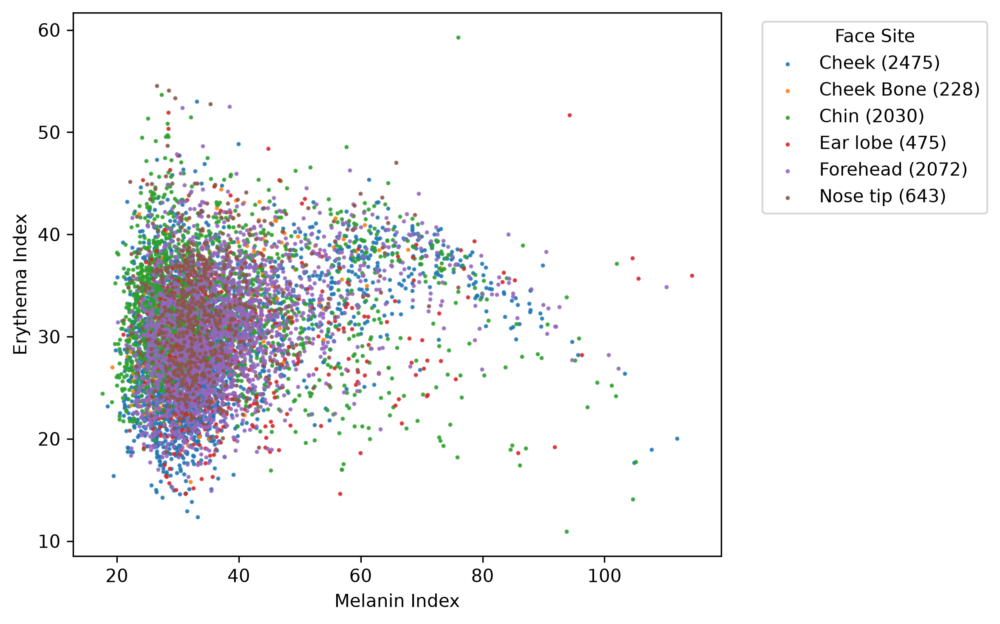

In [7]:
# Visualize melanin vs erythema index
fig, ax = plt.subplots(1, 1, figsize=(8, 5), dpi=300)

for site_id in np.unique(face_sites_clean):
    site_mask = face_sites_clean == site_id
    ax.scatter(face_mi[site_mask], face_ei[site_mask], s=2, alpha=0.8, label=f'{site_names[site_id]} ({site_mask.sum()})')

# ax.set_title('Melanin vs Erythema Index on Face Sites')
ax.set_xlabel('Melanin Index')
ax.set_ylabel('Erythema Index')
ax.legend(title='Face Site', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.savefig('../figures/melanin_vs_erythema_index_on_face_sites.png', bbox_inches='tight')
plt.show()


We apply a Gaussian mixture model with 5 components to approximate the distribution of melanin and erythema indices in the population. This allows us to identify the realistic combinations of these chromophore indices.

In [8]:
from sklearn.mixture import GaussianMixture
from matplotlib.patches import Ellipse
from scipy.stats import chi2

# Define a Function to Draw Ellipses ---
# This function calculates the parameters for drawing an ellipse 
# based on a mean and covariance matrix for a given confidence level.
def draw_ellipse(position, covariance, level=0.95, ax=None, alpha=1.0, edgecolor='black', facecolor='none', **kwargs):
    ax = ax or plt.gca()

    # Convert covariance to principal axes for drawing ellipse
    if covariance.shape == (2, 2):
        U, s, Vt = np.linalg.svd(covariance)
        angle = np.degrees(np.arctan2(U[1, 0], U[0, 0]))
        width, height = 2 * np.sqrt(s)
    else: # spherical or diagonal covariance
        width, height = 2 * np.sqrt(covariance)
        angle = 0
    
    # Calculate the scaling factor for the confidence region
    # For a 2D Gaussian, the squared Mahalanobis distance follows a Chi-squared distribution 
    # with 2 degrees of freedom. We use a critical value for a given confidence level.
    scale_factor = np.sqrt(chi2.ppf(level, 2))

    # Scale the width and height by the factor
    width *= scale_factor
    height *= scale_factor

    # Create the ellipse patch
    ellipse = Ellipse(position, width=width, height=height, angle=angle, 
                      edgecolor=edgecolor, facecolor=facecolor, alpha=alpha, **kwargs)
    ax.add_patch(ellipse)

# Calculate the Mahalanobis distances of points to each GMM component
def mahalanobis_distance(x, gmm):
    distances = np.zeros((x.shape[0], gmm.n_components))
    for i in range(gmm.n_components):
        diff = x - gmm.means_[i]
        inv_cov = gmm.precisions_[i]
        distances[:, i] = np.sqrt(np.einsum('ij,jk,ik->i', diff, inv_cov, diff))
    return distances

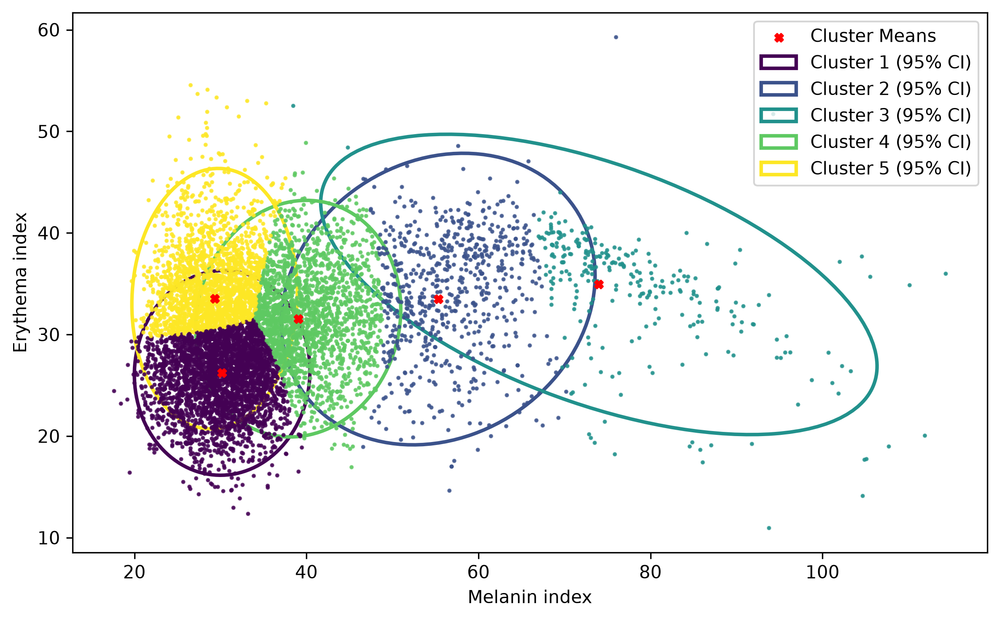

In [9]:
# Fit a Gaussian mixture model to melanin and erythema index
face_cov = np.vstack([face_mi, face_ei]).transpose()
# Initialize and fit GMM
K = 5
gmm = GaussianMixture(n_components=K, covariance_type='full')
gmm.fit(face_cov)


# Predict the cluster labels (Hard Assignment)
labels = gmm.predict(face_cov)

# Confidence level for the ellipses
level = 0.95

# Plot the Data and Confidence Regions ---
fg, ax = plt.subplots(1, 1, figsize=(8, 5), dpi=300)

# Plot the data points, colored by their assigned cluster
ax.scatter(face_cov[:, 0], face_cov[:, 1], c=labels, alpha=0.8, s=2, cmap='viridis', zorder=2)

# Plot the means of each component
ax.scatter(gmm.means_[:, 0], gmm.means_[:, 1], s=20, marker='X', color='red', label='Cluster Means', zorder=3)

# Iterate through each Gaussian component and draw its confidence region
colors = plt.cm.viridis(np.linspace(0, 1, K)) # Get distinct colors for ellipses
for i in range(K):
    position = gmm.means_[i]
    covariance = gmm.covariances_[i] # This is the covariance matrix for 'full' type
    
    draw_ellipse(position, covariance, level=level, ax=ax, edgecolor=colors[i], lw=2, label=f'Cluster {i+1} ({level*100:.0f}% CI)')


#ax.set_title(f'Gaussian Mixture Model with {level*100:.0f}% Confidence Regions')
ax.set_xlabel("Melanin index")
ax.set_ylabel("Erythema index")
ax.legend()
# ax.axis('equal') # Ensures ellipses are not distorted

plt.tight_layout() 
plt.savefig('../figures/gmm_mi_ei_confidence_regions.png', bbox_inches='tight')
plt.show()

# Posterior inference

We use the existing hybrid Gibbs model fitted to the ISSA facial spectra, with 10,000 tuning iterations and 10,000 subsequent iterations, retaining every tenth draw. A compatible checkpoint is reused when available. The downloaded `bvcm_issa_face_posterior.npz` contains 8,033 subject deviations and no labeled residual-covariance state, so it cannot supply the current model's Stage 2 reference. The first run below fits the model on the current 6,338 training spectra and saves a complete compatible checkpoint.

To reduce memory use, the mean subject-specific deviation is accumulated across the same retained draws. Coefficient and hyperparameter draws remain available for posterior summaries.

## Preprocess data


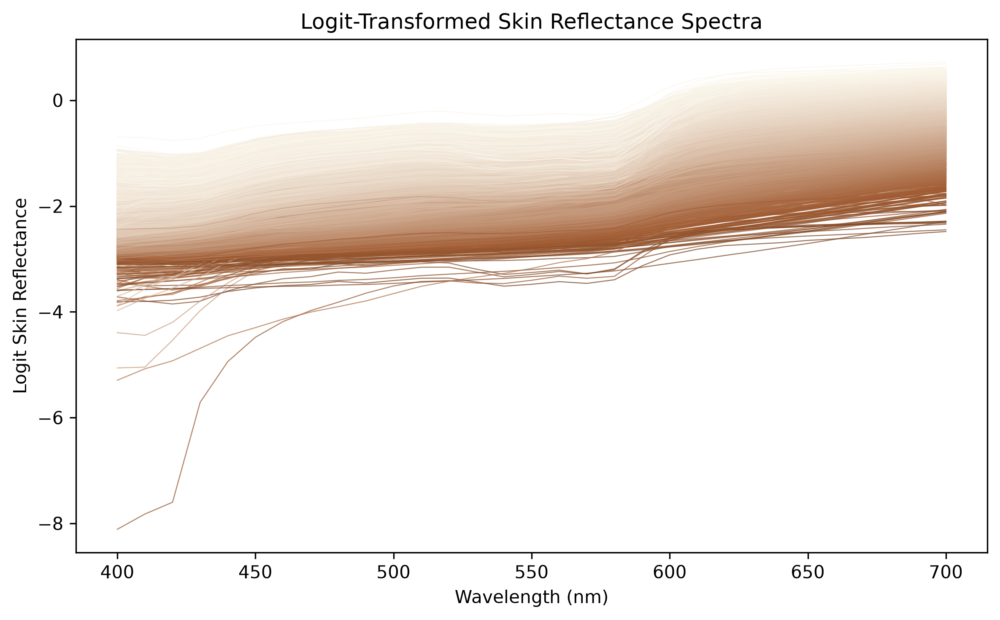

In [10]:
# Logit-transform the spectra for Gaussian process modeling
logit = lambda p: np.log(p / (1 - p))
inv_logit = lambda l: 1 / (1 + np.exp(-l))

logit_face_spectra = logit(face_spectra_clean / 100)  # Scale to [0,1] before logit

train_logit_spectra = logit_face_spectra[train_indices, :]
test_logit_spectra = logit_face_spectra[test_indices, :]

# Visualize the logit-transformed spectra
plt.figure(figsize=(8, 5), dpi=300)
for i in range(logit_face_spectra.shape[0]):
    color = cmap(norm(face_mi_clipped[i]))
    plt.plot(issa_wavelengths, logit_face_spectra[i, :], color=color, alpha=0.7, linewidth=0.6)
plt.title('Logit-Transformed Skin Reflectance Spectra')
plt.xlabel('Wavelength (nm)')
plt.ylabel('Logit Skin Reflectance')
plt.tight_layout()
plt.show()

## Gibbs sampler

In [11]:
# Prepare data for BVCM model
N_subjects, M_wavelengths = face_spectra_clean.shape
t = issa_wavelengths - 550  # Shape: (M,), Centered at 550 nm
L = 150

# A. B-SPLINE BASIS (For Fixed Effects)
df = 20

# B. HSGP BASIS (For Random Effects)
# We use 10 basis functions for subject deviations
m_basis = 10
L_lim = L * 1.2 # Extend the limit slightly beyond the data range

In [12]:
from bvcm_gibbs import BVCM_GibbsSampler
import hashlib

bvcm = BVCM_GibbsSampler(train_logit_spectra, X=train_X, t_grid=t, df=df, m_basis=m_basis, L_lim=L_lim, tau2_beta=1.0, jump_scale=0.01)
checkpoint_path = data_dir / 'bvcm_gibbs_validation_checkpoint.npz'
issa_sha256 = hashlib.sha256(issa_path.read_bytes()).hexdigest()
sampler_sha256 = hashlib.sha256((project_root / 'code' / 'bvcm_gibbs.py').read_bytes()).hexdigest()
fit_settings = np.array([df, m_basis, L_lim, 1.0, 0.01, 10000, 10000], dtype=float)
trace_keys = ['beta_curves', 'ls_z', 'eta_z', 'sigma2']
fit_source = 'refitted_current_gibbs_model'

if checkpoint_path.is_file():
    with np.load(checkpoint_path, allow_pickle=False) as saved:
        if (str(saved['issa_sha256']) != issa_sha256
                or str(saved['sampler_sha256']) != sampler_sha256
                or not np.array_equal(saved['train_indices'], train_indices)
                or not np.array_equal(saved['wavelengths'], issa_wavelengths)
                or not np.array_equal(saved['fit_settings'], fit_settings)):
            raise ValueError('Saved Gibbs checkpoint does not match the data, split, model code, or settings.')
        bvcm_trace = {key: saved[key] for key in trace_keys}
        z_mean = saved['z_mean']
        fit_acceptance_rate = float(saved['acceptance_rate'])
    fit_source = 'compatible_gibbs_checkpoint'
    print(f'Loaded compatible Gibbs checkpoint: {checkpoint_path.name}')
else:
    bvcm.run(draws=10000, tune=10000, store_z_curves=False, progress_every=1000)
    bvcm_trace = bvcm.trace
    z_mean = bvcm.z_mean
    fit_acceptance_rate = bvcm.acc_count / 20000
    np.savez_compressed(
        checkpoint_path,
        **{key: np.asarray(bvcm_trace[key]) for key in trace_keys},
        z_mean=z_mean, train_indices=train_indices, test_indices=test_indices,
        wavelengths=issa_wavelengths, fit_settings=fit_settings,
        issa_sha256=issa_sha256, sampler_sha256=sampler_sha256,
        acceptance_rate=fit_acceptance_rate,
    )
    print(f'Saved Gibbs checkpoint: {checkpoint_path.name}')

ls_z = np.mean(bvcm_trace['ls_z'])
eta_z = np.mean(bvcm_trace['eta_z'])
sigma2 = np.mean(bvcm_trace['sigma2'])
print(f'Posterior means: length scale={ls_z:.6f}, amplitude={eta_z:.6f}, noise variance={sigma2:.8f}')


Loaded compatible Gibbs checkpoint: bvcm_gibbs_validation_checkpoint.npz
Posterior means: length scale=45.844508, amplitude=0.106108, noise variance=0.00022890


## Posterior visualization

### Coefficient function estimation

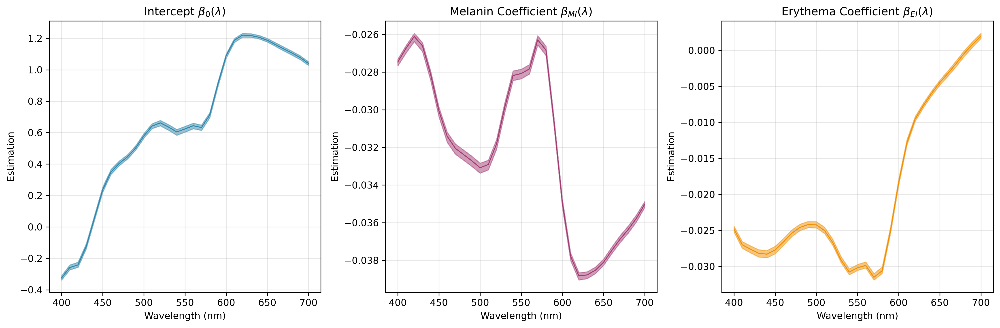

In [13]:
# Visualization
# Extract posterior means and credible intervals for beta curves
post_betas = np.stack(bvcm_trace['beta_curves'])
post_betas_mean = np.mean(post_betas, axis=0)
post_betas_lower = np.percentile(post_betas, 2.5, axis=0)
post_betas_upper = np.percentile(post_betas, 97.5, axis=0)

fig, axes = plt.subplots(1, 3, figsize=(15, 5), dpi=300)

# Plot Intercept (beta_0)
ax = axes[0]
ax.plot(issa_wavelengths, post_betas_mean[0, :], color='#2E86AB', linewidth=1)
ax.fill_between(issa_wavelengths, 
                post_betas_lower[0, :],
                post_betas_upper[0, :],
                alpha=0.5, color='#2E86AB')
ax.set_title(r"Intercept $\beta_0(\lambda)$")
ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Estimation")
ax.grid(alpha=0.3)


# Plot Slope for MI (beta_mi)
ax = axes[1]
ax.plot(issa_wavelengths, post_betas_mean[1, :], color='#A23B72', linewidth=1)
ax.fill_between(issa_wavelengths, 
                     post_betas_lower[1, :],
                     post_betas_upper[1, :],
                     alpha=0.5, color='#A23B72')
ax.set_title(r"Melanin Coefficient $\beta_{MI}(\lambda)$")
ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Estimation")
ax.grid(alpha=0.3)

# Plot Slope for EI (beta_ei)
ax = axes[2]
ax.plot(issa_wavelengths, post_betas_mean[2, :], color='#F18F01', linewidth=1)
ax.fill_between(issa_wavelengths, 
                     post_betas_lower[2, :],
                     post_betas_upper[2, :],
                     alpha=0.5, color='#F18F01')
ax.set_title(r"Erythema Coefficient $\beta_{EI}(\lambda)$")
ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Estimation")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('../figures/beta_curves_estimation.png', bbox_inches='tight')
plt.show()

### Predict reflectance spectra given MI and EI

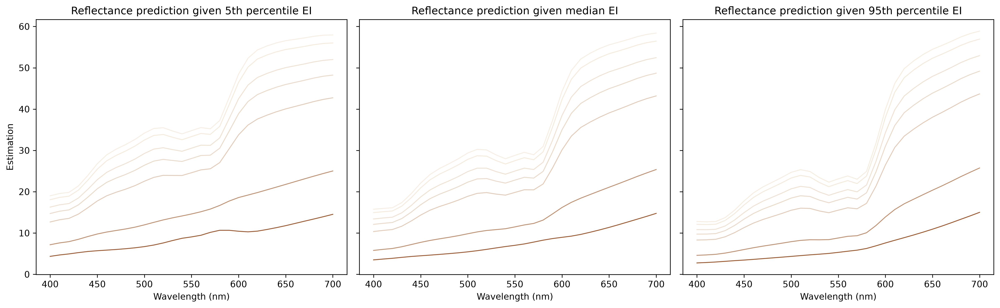

In [14]:
# Visualization
fig, axes = plt.subplots(1, 3, figsize=(16, 5), dpi=300, sharey=True)

# Plot prediction (beta0 + beta_mi * MI + 5th percentile of beta_ei * EI)
ax = axes[0]
for prop in [1, 5, 25, 50, 75, 95, 99]:  # Percentiles of MI
    mi_percentile = np.percentile(face_mi, prop)
    bvcm_est = post_betas_mean[0, :] + post_betas_mean[1, :] * mi_percentile + post_betas_mean[2, :] * np.percentile(face_ei, 5)  # Use 5th percentile of EI for this plot
    bvcm_spectrum = inv_logit(bvcm_est) * 100  # Convert back to reflectance percentage
    color = cmap(norm(100 * np.log10(100 / bvcm_spectrum[28])))  # Color based on the melanin index corresponding to the spectrum
    ax.plot(issa_wavelengths, bvcm_spectrum, color=color, linewidth=1, alpha=1)

ax.set_title("Reflectance prediction given 5th percentile EI")
ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Estimation")

# Plot prediction (beta0 + beta_mi * MI + median of beta_ei * EI)
ax = axes[1]
for prop in [1, 5, 25, 50, 75, 95, 99]:  # Percentiles of MI
    mi_percentile = np.percentile(face_mi, prop)
    bvcm_est = post_betas_mean[0, :] + post_betas_mean[1, :] * mi_percentile + post_betas_mean[2, :] * np.median(face_ei)
    bvcm_spectrum = inv_logit(bvcm_est) * 100  # Convert back to reflectance percentage
    color = cmap(norm(100 * np.log10(100 / bvcm_spectrum[28])))  # Color based on the melanin index corresponding to the spectrum
    ax.plot(issa_wavelengths, bvcm_spectrum, color=color, linewidth=1, alpha=1)

ax.set_title("Reflectance prediction given median EI")
ax.set_xlabel("Wavelength (nm)")

# Plot prediction (beta0 + beta_mi * MI + 95th percentile of beta_ei * EI)
ax = axes[2]
for prop in [1, 5, 25, 50, 75, 95, 99]:  # Percentiles of MI
    mi_percentile = np.percentile(face_mi, prop)
    bvcm_est = post_betas_mean[0, :] + post_betas_mean[1, :] * mi_percentile + post_betas_mean[2, :] * np.percentile(face_ei, 95)  # Use 95th percentile of EI for this plot
    bvcm_spectrum = inv_logit(bvcm_est) * 100  # Convert back to reflectance percentage
    color = cmap(norm(100 * np.log10(100 / bvcm_spectrum[28])))  # Color based on the melanin index corresponding to the spectrum
    ax.plot(issa_wavelengths, bvcm_spectrum, color=color, linewidth=1, alpha=1)

ax.set_title("Reflectance prediction given 95th percentile EI")
ax.set_xlabel("Wavelength (nm)")

#plt.suptitle(f'BVCM Reflectance Predictions for Different MI Percentiles Given EI', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('../figures/bvcm_reflectance_predictions_for_different_mi_percentiles_given_ei.png', bbox_inches='tight')
plt.show()

**Remark:** Across various levels of the erythema index, the predicted reflectance spectra exhibit a W-shape at low melanin indices and an increasing shape at high melanin indices. This finding is consistent with the shape analysis within ISSA.

### Subject-specific deviation 

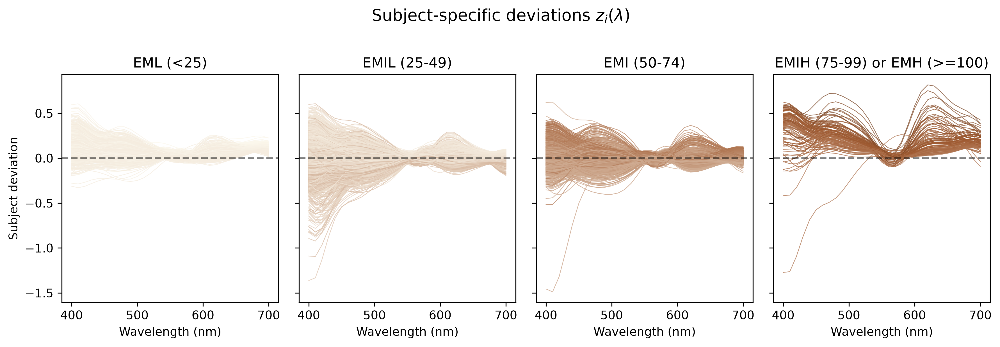

In [15]:
# 1. Extract the Posterior Mean of z_curves
# Shape: (N_subjects, M_timepoints)
# We average over all MCMC samples (chains and draws) to get the "Best Estimate" curve for each person.
# z_mean = trace.posterior["z_curves"].mean(dim=["chain", "draw"]).values
# z_mean was accumulated from retained draws, or loaded from the matching checkpoint.

# 2. Extract Global Fixed Effects (Mean trends)


# Pick subjects for different melanin index levels
# Select subjects with low, medium, and high melanin index
train_mi = face_mi[train_indices]
train_df = face_df.iloc[train_indices, :]

# --- Visualization ---
fig, axes = plt.subplots(1, 4, figsize=(12, 4), dpi=300, sharey=True)

# Plot ISSA spectra
ax = axes[0]
train_eml_mask = (train_df['Eumelanin Class'] == 'EML (<25)')
train_eml_indices = np.where(train_eml_mask)[0]
for i in train_eml_indices:
    color = cmap(norm(train_mi[i]))
    ax.plot(issa_wavelengths, z_mean[i, :], color=color, alpha=0.7, linewidth=0.6)
ax.set_title('EML (<25)')
ax.set_ylabel('Subject deviation')
ax.set_xlabel('Wavelength (nm)')
ax.axhline(0, color='k', linestyle='--', alpha=0.5)

# Plot ISSA spectra
ax = axes[1]
train_emil_mask = (train_df['Eumelanin Class'] == 'EMIL (25-49)')
train_emil_indices = np.where(train_emil_mask)[0]
for i in train_emil_indices:
    color = cmap(norm(train_mi[i]))
    ax.plot(issa_wavelengths, z_mean[i, :], color=color, alpha=0.7, linewidth=0.6)
ax.set_title('EMIL (25-49)')
ax.set_xlabel('Wavelength (nm)')
ax.axhline(0, color='k', linestyle='--', alpha=0.5)

# Plot ISSA spectra
ax = axes[2]
train_emi_mask = (train_df['Eumelanin Class'] == 'EMI (50-74)')
train_emi_indices = np.where(train_emi_mask)[0]
for i in train_emi_indices:
    color = cmap(norm(train_mi[i]))
    ax.plot(issa_wavelengths, z_mean[i, :], color=color, alpha=0.7, linewidth=0.6)
ax.set_title('EMI (50-74)')
ax.set_xlabel('Wavelength (nm)')
ax.axhline(0, color='k', linestyle='--', alpha=0.5)

# Plot ISSA spectra
ax = axes[3]
train_emh_mask = (train_df['Eumelanin Class'] == 'EMIH (75-99)') | (train_df['Eumelanin Class'] == 'EMH (>=100)')
train_emh_indices = np.where(train_emh_mask)[0]
for i in train_emh_indices:
    color = cmap(norm(train_mi[i]))
    ax.plot(issa_wavelengths, z_mean[i, :], color=color, alpha=0.7, linewidth=0.6)
ax.set_title('EMIH (75-99) or EMH (>=100)')
ax.set_xlabel('Wavelength (nm)')
ax.axhline(0, color='k', linestyle='--', alpha=0.5)

plt.suptitle(r'Subject-specific deviations $z_i(\lambda)$', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

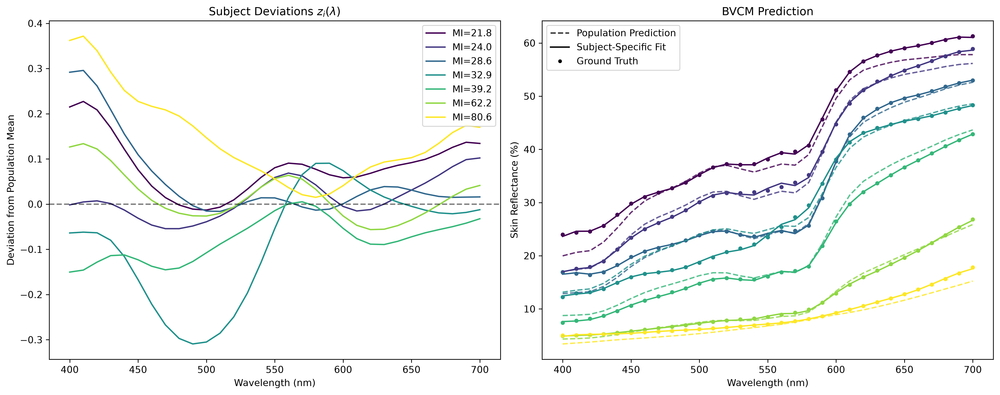

In [16]:
# 1. Extract the Posterior Mean of z_curves
# Shape: (N_subjects, M_timepoints)
# We average over all MCMC samples (chains and draws) to get the "Best Estimate" curve for each person.
# z_mean = trace.posterior["z_curves"].mean(dim=["chain", "draw"]).values
# z_mean was accumulated from retained draws, or loaded from the matching checkpoint.

# 2. Extract Global Fixed Effects (Mean trends)


# Pick subjects for different melanin index levels
# Select subjects with low, medium, and high melanin index
train_mi = face_mi[train_indices]
sorted_mi_indices = np.argsort(train_mi)
positions = ((len(sorted_mi_indices) - 1) * np.array([1, 5, 25, 50, 75, 95, 99]) / 100).astype(int)
percentile_indices = sorted_mi_indices[positions]

# --- Visualization ---
fig, axes = plt.subplots(1, 2, figsize=(15, 6), dpi=300)

# --- PLOT A: The Isolated Deviations (z_i) ---
# This shows pure "random effects". 
# Curves above 0 mean the subject is consistently higher than expected.
# Curves below 0 mean the subject is lower than expected.

# Highlight specific subjects with different melanin levels
num_colors = len(percentile_indices)
colors = plt.get_cmap('viridis', num_colors)
for i, idx in enumerate(percentile_indices):
    axes[0].plot(issa_wavelengths, z_mean[idx, :], linewidth=1.5, color=colors(i), 
                 label=f"MI={train_mi[idx]:.1f}")

axes[0].axhline(0, color='k', linestyle='--', alpha=0.5)
axes[0].set_title(r"Subject Deviations $z_i(\lambda)$")
axes[0].set_ylabel("Deviation from Population Mean")
axes[0].set_xlabel("Wavelength (nm)")
axes[0].legend(loc='upper right')

# --- PLOT B: Total Trajectories (Reconstructed) ---
# This compares the Model's "Personalized Prediction" vs. Actual Data
# Prediction_i = beta0 + beta1*x_i + z_i

# We only plot the 3 highlighted subjects to avoid clutter
for i, idx in enumerate(percentile_indices):
    # Global trend (fixed effects only, without subject-specific deviation)
    global_trend = train_X[idx] @ post_betas_mean

    # Reconstruct the mean prediction for this subject (global + subject-specific)
    # Note: We must use the specific x_i for this subject
    subject_pred = global_trend + z_mean[idx, :]

    # Plot Global Trend (Dashed Line) - only label once
    axes[1].plot(issa_wavelengths, 100 * inv_logit(global_trend), linewidth=1.5, color=colors(i),
                 linestyle='--', alpha=0.8)

    # Plot Prediction (Solid Line) - label with subject info and general label on first
    axes[1].plot(issa_wavelengths, 100 * inv_logit(subject_pred), linewidth=1.5, color=colors(i))

    # Plot Actual Data Points (Dots) - only label once
    axes[1].scatter(issa_wavelengths, train_spectra[idx, :], s=12, color=colors(i))

# Create a custom legend for Plot B to explain the line styles
from matplotlib.lines import Line2D
custom_lines = [
    Line2D([0], [0], color='black', linestyle='--', alpha=0.8, lw=1.5),
    Line2D([0], [0], color='black', linestyle='-', lw=1.5),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='black', markersize=5)
]
axes[1].legend(custom_lines, ['Population Prediction', 'Subject-Specific Fit', 'Ground Truth'], loc='upper left')

axes[1].set_title("BVCM Prediction")
axes[1].set_ylabel("Skin Reflectance (%)")
axes[1].set_xlabel("Wavelength (nm)")

plt.tight_layout()
plt.show()

# Model diagnostics and evaluation

## Evaluation on training data

In [17]:
# Evaluate regression performance

# 1. Calculate predictions for all subjects
# Population-level predictions (fixed effects only)
pop_predictions = train_X @ post_betas_mean

# Subject-specific predictions (fixed + random effects)
subj_predictions = pop_predictions + z_mean

# Transform back to original scale
pop_predictions_orig = 100 * inv_logit(pop_predictions)
subj_predictions_orig = 100 * inv_logit(subj_predictions)

# 2. Calculate metrics
# Total variance in the data
total_var = np.var(train_spectra, axis=0).mean()

# Residuals for population-level model
pop_residuals = train_spectra - pop_predictions_orig
pop_ss_res = np.sum(pop_residuals**2)
pop_ss_tot = np.sum((train_spectra - np.mean(train_spectra, axis=0))**2)
pop_r2 = 1 - (pop_ss_res / pop_ss_tot)
pop_rmse = np.sqrt(np.mean(pop_residuals**2))

# Residuals for subject-specific model
subj_residuals = train_spectra - subj_predictions_orig
subj_ss_res = np.sum(subj_residuals**2)
subj_ss_tot = np.sum((train_spectra - np.mean(train_spectra, axis=0))**2)
subj_r2 = 1 - (subj_ss_res / subj_ss_tot)
subj_rmse = np.sqrt(np.mean(subj_residuals**2))

# Variance explained by random effects
var_explained_by_random = (pop_ss_res - subj_ss_res) / pop_ss_tot

# Create summary table
eval_results = pd.DataFrame({
    'Model': ['Population-Level (Fixed Effects)', 'Subject-Specific (Fixed + Random)'],
    'R²': [pop_r2, subj_r2],
    'RMSE (%)': [pop_rmse, subj_rmse],
    'MAE (%)': [np.mean(np.abs(pop_residuals)), np.mean(np.abs(subj_residuals))]
})

eval_results

# print("\n" + "="*60)
# print("MODEL EVALUATION SUMMARY on TRAINING DATA")
# print("="*60)
# print(eval_results.to_string(index=False))
# print("\n" + "-"*60)
# print(f"Additional Variance Explained by Random Effects: {var_explained_by_random:.4f}")
# print(f"Total Variance in Data: {total_var:.4f}")
# print("="*60)

,Model,R²,RMSE (%),MAE (%)
0,Population-Level (Fixed Effects),0.965248,1.411095,1.053455
1,Subject-Specific (Fixed + Random),0.999319,0.197515,0.131818


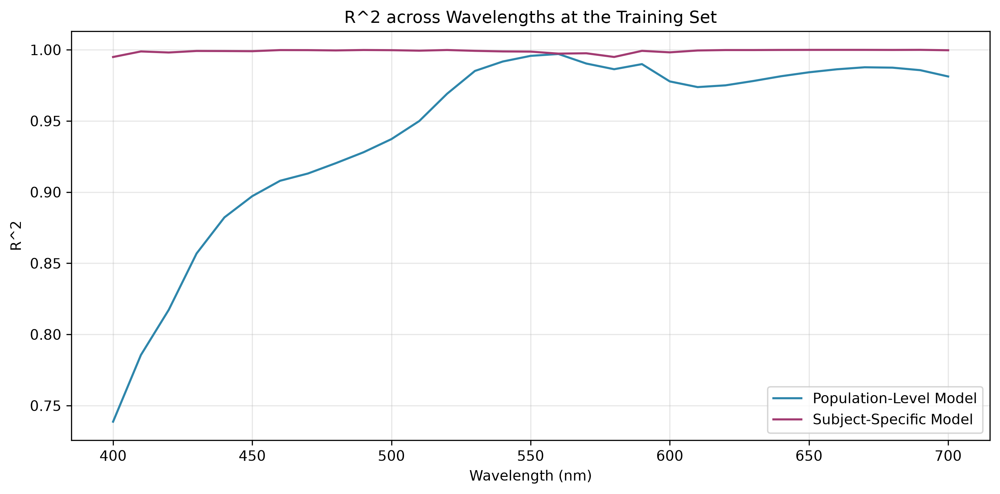

In [18]:
# Calculate the R square for each wavelength separately to see how well the model fits across the wavelength spectrum. 
# This can reveal if the model performs better in certain wavelength regions (e.g., where melanin absorption is stronger).
# Residuals for population-level model
pop_ss_res_per_wavelength = np.sum(pop_residuals**2, axis=0)
pop_ss_tot_per_wavelength = np.sum((train_spectra - np.mean(train_spectra, axis=0))**2, axis=0)
pop_r2_per_wavelength = 1 - (pop_ss_res_per_wavelength / pop_ss_tot_per_wavelength)
# Residuals for subject-specific model
subj_ss_res_per_wavelength = np.sum(subj_residuals**2, axis=0)
subj_ss_tot_per_wavelength = np.sum((train_spectra - np.mean(train_spectra, axis=0))**2, axis=0)
subj_r2_per_wavelength = 1 - (subj_ss_res_per_wavelength / subj_ss_tot_per_wavelength)

# Plot R² across wavelengths
plt.figure(figsize=(10, 5), dpi=300)
plt.plot(issa_wavelengths, pop_r2_per_wavelength, label='Population-Level Model', color='#2E86AB')
plt.plot(issa_wavelengths, subj_r2_per_wavelength, label='Subject-Specific Model', color='#A23B72')
plt.title("R^2 across Wavelengths at the Training Set")
plt.xlabel("Wavelength (nm)")
plt.ylabel("R^2")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

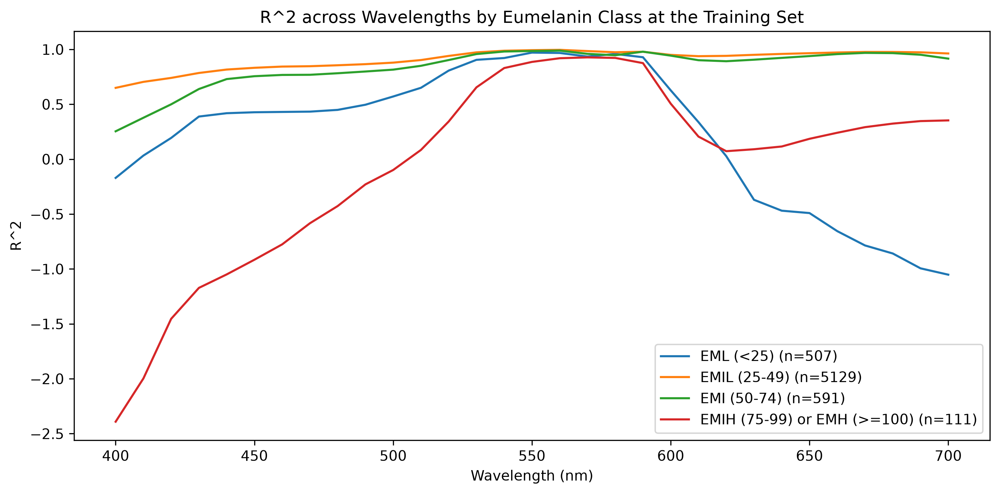

In [19]:
# Calculate the R square for each wavelength separately by eumelanin class to see if the model fits better for certain skin types.
# We will calculate R² for each eumelanin class and plot them together.
# Define a function to calculate R² for a given set of indices
def calculate_r2_for_indices(indices, spectra, predictions):
    if len(indices) == 0:
        return np.zeros(spectra.shape[1])  # Return zeros if no samples in this class
    residuals = spectra[indices] - predictions[indices]
    ss_res_per_wavelength = np.sum(residuals**2, axis=0)
    ss_tot_per_wavelength = np.sum((spectra[indices] - np.mean(spectra[indices], axis=0))**2, axis=0)
    r2_per_wavelength = 1 - (ss_res_per_wavelength / ss_tot_per_wavelength)
    return r2_per_wavelength
# Calculate R² for each eumelanin class
fig, ax = plt.subplots(1, 1, figsize=(10, 5), dpi=300)
for em_class in ['EML (<25)', 'EMIL (25-49)', 'EMI (50-74)']:
    class_mask = (train_df['Eumelanin Class'] == em_class)
    class_indices = np.where(class_mask)[0]
    r2_per_wavelength = calculate_r2_for_indices(class_indices, train_spectra, pop_predictions_orig)
    plt.plot(issa_wavelengths, r2_per_wavelength, label=f'{em_class} (n={len(class_indices)})')
class_mask = ((train_df['Eumelanin Class'] == 'EMIH (75-99)') | (train_df['Eumelanin Class'] == 'EMH (>=100)'))
class_indices = np.where(class_mask)[0]
r2_per_wavelength = calculate_r2_for_indices(class_indices, train_spectra, pop_predictions_orig)
plt.plot(issa_wavelengths, r2_per_wavelength, label=f'EMIH (75-99) or EMH (>=100) (n={len(class_indices)})')

plt.title("R^2 across Wavelengths by Eumelanin Class at the Training Set")
plt.xlabel("Wavelength (nm)")
plt.ylabel("R^2")
plt.legend()
plt.tight_layout()
plt.show()

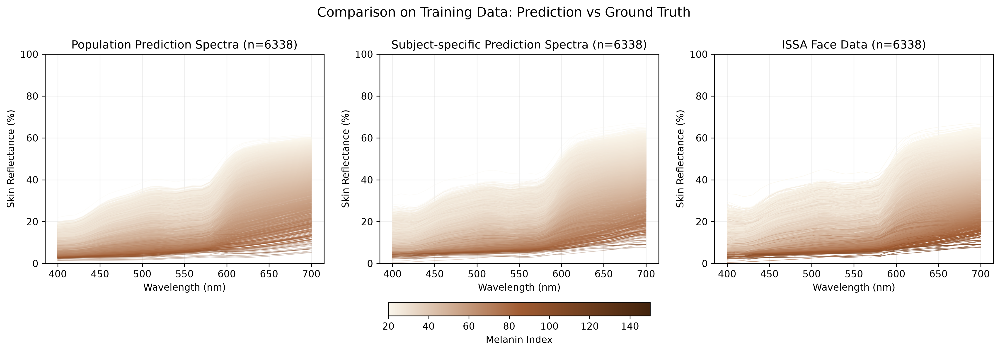

In [20]:
# Visualize the generated spectra compared to original ISSA data
fig, axes = plt.subplots(1, 3, figsize=(18, 5), dpi=300)

# Plot 1: Prediction population spectra
ax = axes[0]
for i in range(train_spectra.shape[0]):  # Plot subset to avoid clutter
    color = cmap(norm(face_mi_clipped[train_indices[i]]))
    ax.plot(issa_wavelengths, pop_predictions_orig[i, :], color=color, alpha=0.3, linewidth=0.6)
ax.set_title(f'Population Prediction Spectra (n={train_spectra.shape[0]})')
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('Skin Reflectance (%)')
ax.set_ylim([0, 100])
ax.grid(alpha=0.2)

# Plot 2: Subject-specific Prediction Spectra
ax = axes[1]
for i in range(train_spectra.shape[0]):  # Plot subset to avoid clutter
    color = cmap(norm(face_mi_clipped[train_indices[i]]))
    ax.plot(issa_wavelengths, subj_predictions_orig[i, :], color=color, alpha=0.3, linewidth=0.6)
ax.set_title(f'Subject-specific Prediction Spectra (n={train_spectra.shape[0]})')
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('Skin Reflectance (%)')
ax.set_ylim([0, 100])
ax.grid(alpha=0.2)

# Plot 3: Original ISSA spectra for comparison
ax = axes[2]
for i in range(train_spectra.shape[0]):
    color = cmap(norm(face_mi_clipped[train_indices[i]]))
    ax.plot(issa_wavelengths, train_spectra[i, :], color=color, alpha=0.7, linewidth=0.6)
ax.set_title(f'ISSA Face Data (n={train_spectra.shape[0]})')
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('Skin Reflectance (%)')
ax.set_ylim([0, 100])
ax.grid(alpha=0.2)

# Add shared colorbar
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes.ravel().tolist(), orientation="horizontal", 
                    fraction=0.05, pad=0.15)
cbar.set_label("Melanin Index")

plt.suptitle('Comparison on Training Data: Prediction vs Ground Truth', 
             fontsize=14, y=1.02)
plt.show()

## Evaluation on test data

In [21]:
# Evaluate regression performance

# 1. Calculate predictions for all subjects
# Population-level predictions (fixed effects only)
test_pop_predictions = test_X @ post_betas_mean

# Transform back to original scale
test_pop_predictions_orig = 100 * inv_logit(test_pop_predictions)

# 2. Calculate metrics
# Total variance in the data
total_var = np.var(test_spectra, axis=0).mean()

# Residuals for population-level model
test_pop_residuals = test_spectra - test_pop_predictions_orig
pop_ss_res = np.sum(test_pop_residuals**2)
pop_ss_tot = np.sum((test_spectra - np.mean(test_spectra, axis=0))**2)
pop_r2 = 1 - (pop_ss_res / pop_ss_tot)
pop_rmse = np.sqrt(np.mean(test_pop_residuals**2))

# Create summary table
eval_results = pd.DataFrame({
    'Model': ['Population-Level (Fixed Effects)'],
    'R²': [pop_r2],
    'RMSE (%)': [pop_rmse],
    'MAE (%)': [np.mean(np.abs(test_pop_residuals))]
})

eval_results

# print("\n" + "="*60)
# print("MODEL EVALUATION SUMMARY on TEST DATA")
# print("="*60)
# print(eval_results.to_string(index=False))
# print("\n" + "-"*60)
# print(f"Total Variance in Data: {total_var:.4f}")
# print("="*60)

,Model,R²,RMSE (%),MAE (%)
0,Population-Level (Fixed Effects),0.964578,1.428091,1.06963


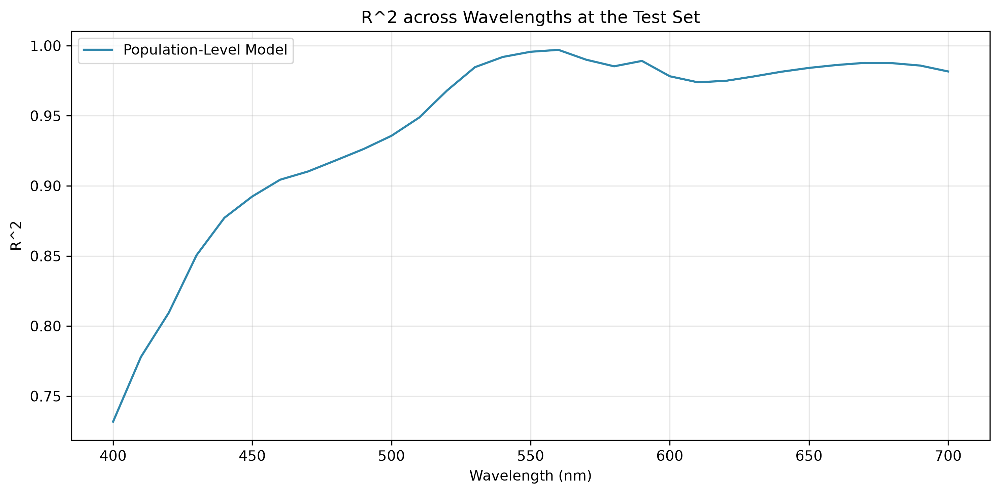

In [22]:
# Calculate the R square for each wavelength separately to see how well the model fits across the spectrum
# Residuals for population-level model
test_pop_ss_res_per_wavelength = np.sum(test_pop_residuals**2, axis=0)
test_pop_ss_tot_per_wavelength = np.sum((test_spectra - np.mean(test_spectra, axis=0))**2, axis=0)
test_pop_r2_per_wavelength = 1 - (test_pop_ss_res_per_wavelength / test_pop_ss_tot_per_wavelength)

# Plot R² across wavelengths
plt.figure(figsize=(10, 5), dpi=300)
plt.plot(issa_wavelengths, test_pop_r2_per_wavelength, label='Population-Level Model', color='#2E86AB')
plt.title("R^2 across Wavelengths at the Test Set")
plt.xlabel("Wavelength (nm)")
plt.ylabel("R^2")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

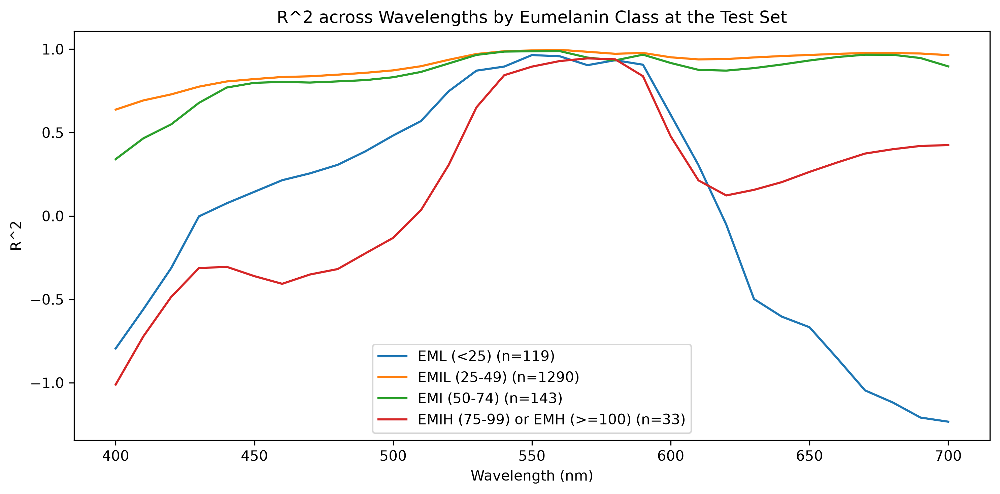

In [23]:
# Calculate the R square for each wavelength separately by eumelanin class to see if the model fits better for certain skin types.
# We will calculate R² for each eumelanin class and plot them together.
# Calculate R² for each eumelanin class
test_df = face_df.iloc[test_indices, :]
fig, ax = plt.subplots(1, 1, figsize=(10, 5), dpi=300)
for em_class in ['EML (<25)', 'EMIL (25-49)', 'EMI (50-74)']:
    class_mask = (test_df['Eumelanin Class'] == em_class)
    class_indices = np.where(class_mask)[0]
    r2_per_wavelength = calculate_r2_for_indices(class_indices, test_spectra, test_pop_predictions_orig)
    plt.plot(issa_wavelengths, r2_per_wavelength, label=f'{em_class} (n={len(class_indices)})')
class_mask = ((test_df['Eumelanin Class'] == 'EMIH (75-99)') | (test_df['Eumelanin Class'] == 'EMH (>=100)'))
class_indices = np.where(class_mask)[0]
r2_per_wavelength = calculate_r2_for_indices(class_indices, test_spectra, test_pop_predictions_orig)
plt.plot(issa_wavelengths, r2_per_wavelength, label=f'EMIH (75-99) or EMH (>=100) (n={len(class_indices)})')

plt.title("R^2 across Wavelengths by Eumelanin Class at the Test Set")
plt.xlabel("Wavelength (nm)")
plt.ylabel("R^2")
plt.legend()
plt.tight_layout()
plt.show()

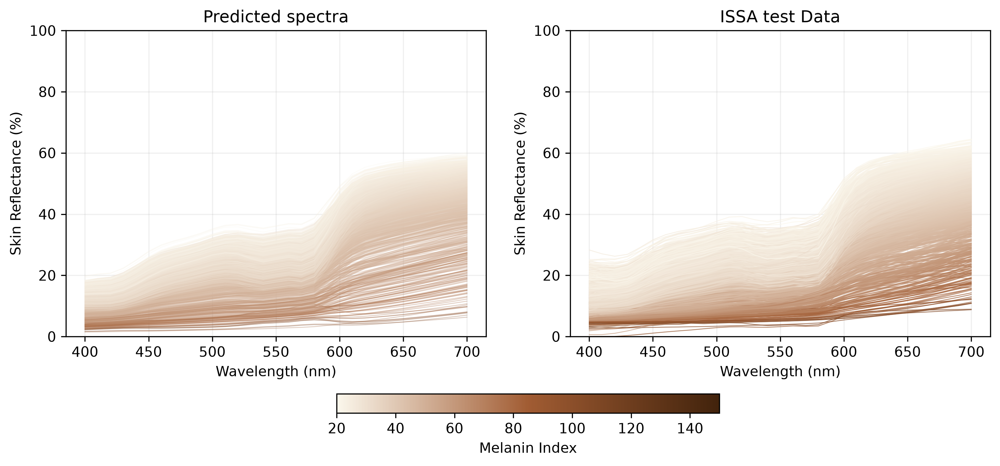

In [24]:
# Visualize the generated spectra compared to original ISSA data
fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=300)

# Plot 1: Prediction population spectra
ax = axes[0]
for i in range(test_spectra.shape[0]):  # Plot subset to avoid clutter
    color = cmap(norm(face_mi_clipped[test_indices[i]]))
    ax.plot(issa_wavelengths, test_pop_predictions_orig[i, :], color=color, alpha=0.3, linewidth=0.6)
#ax.set_title(f'Prediction Spectra (n={test_spectra.shape[0]})')
ax.set_title(f'Predicted spectra')
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('Skin Reflectance (%)')
ax.set_ylim([0, 100])
ax.grid(alpha=0.2)

# Plot 2: Original ISSA spectra for comparison
ax = axes[1]
for i in range(test_spectra.shape[0]):
    color = cmap(norm(face_mi_clipped[test_indices[i]]))
    ax.plot(issa_wavelengths, test_spectra[i, :], color=color, alpha=0.7, linewidth=0.6)
#ax.set_title(f'ISSA test Data (n={test_spectra.shape[0]})')
ax.set_title(f'ISSA test Data')
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('Skin Reflectance (%)')
ax.set_ylim([0, 100])
ax.grid(alpha=0.2)

# Add shared colorbar
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes.ravel().tolist(), orientation="horizontal", 
                    fraction=0.05, pad=0.15)
cbar.set_label("Melanin Index")

#plt.suptitle('Comparison on Test Data: Prediction vs Ground Truth', fontsize=14, y=1.02)
plt.savefig('../figures/predicted_vs_issa_test_spectra.png', bbox_inches='tight')
plt.show()

# Synthetic spectra generation

This section demonstrates how to generate realistic synthetic skin reflectance.

1. Choromophore Index Sampling: Sample melanin variable (MEL) and hemoglobin variable (HEM) pairs from the fitted GMM to ensure biologically plausible combinations.
2. Spectral Prediction: For each sampled (MEL, HEM) pair, use the BVCM fixed effects (population-level coefficients) to predict the corresponding skin reflectance spectrum. Then add subject-specific random effects to introduce realistic individual variation.

   + The new subject-specific deviation $Z^*$ is sampled from $p(Z^*\mid Y)=\int p(Z^*\mid Z) p(Z\mid Y) dZ=p(Z^*)$, where the last equality holds as $Z^*$ is independent to $Z$.

In [25]:
# Sample chromophore indices from the fitted GMM
num_samples = 3000

# Sample from the GMM
np.random.seed(42) # For reproducibility
sampled_cov, sampled_labels = gmm.sample(n_samples=num_samples)
# print(f"\nSampled {num_samples} curves from the GMM")

from bvcm_gibbs import spectral_density_matern

# Generate skin reflectance spectra for the sampled chromophore indices

# 1. Calculate population-level predictions (fixed effects only)
sampled_X = np.column_stack((np.ones(num_samples), sampled_cov))  # Shape: (num_samples, 3)
pop_pred_samples = sampled_X @ post_betas_mean  # Shape: (num_samples, M_wavelengths)
synthetic_pop_spectra = 100 * inv_logit(pop_pred_samples)

# 2. Add subject-specific random effects
# Sample random deviations from the learned GP covariance structure
# Get the covariance matrix from the trace
psd = spectral_density_matern(bvcm.omega, ls_z)
prior_var = eta_z**2 * psd
basis_scale = np.sqrt(prior_var)
# Generate num_samples standard normal vectors and transform
np.random.seed(42)  # For reproducibility
w_z = np.random.randn(num_samples, m_basis) * basis_scale[None, :]
z_samples = w_z @ bvcm.Phi.T

# 3. Combine fixed and random effects, then transform to original scale
synthetic_logit_spectra = pop_pred_samples + z_samples
synthetic_spectra = 100 * inv_logit(synthetic_logit_spectra)
sampled_mi = 100 * np.log10(100 / synthetic_spectra[:, 28])

# print(f"\nGenerated {num_samples} synthetic skin reflectance spectra")
# print(f"Synthetic spectra range: [{synthetic_spectra.min():.2f}%, {synthetic_spectra.max():.2f}%]")
# print(f"Shape: {synthetic_spectra.shape} (samples, wavelengths)")

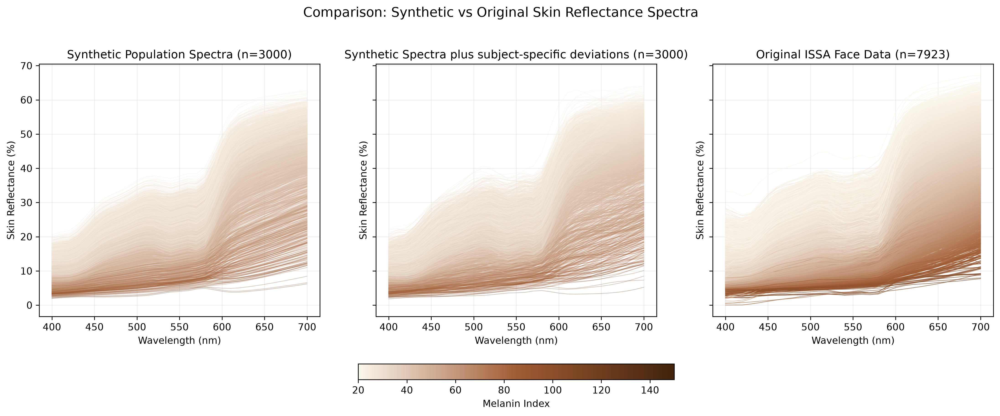

In [26]:
# Visualize the generated spectra compared to original ISSA data
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True, dpi=300)

# Clip sampled MI for colormap
sampled_mi_clipped = np.clip(sampled_mi, 20, 150)

# Plot 1: Synthetic population spectra
ax = axes[0]
for i in range(num_samples):  # Plot subset to avoid clutter
    color = cmap(norm(sampled_mi_clipped[i]))
    ax.plot(issa_wavelengths, synthetic_pop_spectra[i, :], color=color, alpha=0.3, linewidth=0.6)
ax.set_title(f'Synthetic Population Spectra (n={num_samples})')
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('Skin Reflectance (%)')
# ax.set_ylim([0, 100])
ax.grid(alpha=0.2)

# Plot 2: Synthetic spectra plus subject-specific deviations
ax = axes[1]
for i in range(num_samples):  # Plot subset to avoid clutter
    color = cmap(norm(sampled_mi_clipped[i]))
    ax.plot(issa_wavelengths, synthetic_spectra[i, :], color=color, alpha=0.3, linewidth=0.6)
ax.set_title(f'Synthetic Spectra plus subject-specific deviations (n={num_samples})')
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('Skin Reflectance (%)')
# ax.set_ylim([0, 100])
ax.grid(alpha=0.2)

# Plot 3: Original ISSA spectra for comparison
ax = axes[2]
for i in range(face_spectra_clean.shape[0]):
    color = cmap(norm(face_mi_clipped[i]))
    ax.plot(issa_wavelengths, face_spectra_clean[i, :], color=color, alpha=0.7, linewidth=0.6)
ax.set_title(f'Original ISSA Face Data (n={face_spectra_clean.shape[0]})')
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('Skin Reflectance (%)')
# ax.set_ylim([0, 100])
ax.grid(alpha=0.2)

# Add shared colorbar
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes.ravel().tolist(), orientation="horizontal", 
                    fraction=0.05, pad=0.15)
cbar.set_label("Melanin Index")

plt.suptitle('Comparison: Synthetic vs Original Skin Reflectance Spectra', 
             fontsize=14, y=1.02)
plt.show()

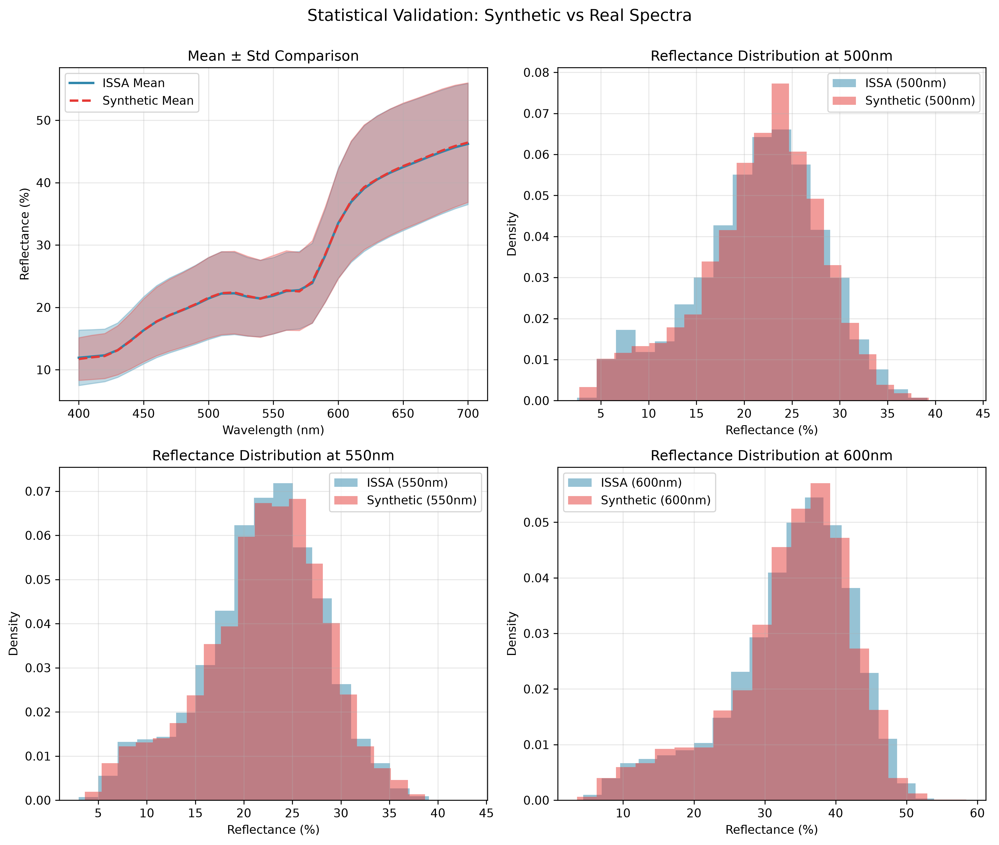

In [27]:
# Statistical comparison between synthetic and real data
fig, axes = plt.subplots(2, 2, figsize=(12, 10), dpi=300)

# Plot 1: Mean spectra comparison
ax = axes[0, 0]
ax.plot(issa_wavelengths, face_spectra.mean(axis=0), 
        color='#2E86AB', linewidth=2, label='ISSA Mean')
ax.fill_between(issa_wavelengths, 
                face_spectra.mean(axis=0) - face_spectra.std(axis=0),
                face_spectra.mean(axis=0) + face_spectra.std(axis=0),
                alpha=0.3, color='#2E86AB')
ax.plot(issa_wavelengths, synthetic_spectra.mean(axis=0), 
        color='#E53935', linewidth=2, label='Synthetic Mean', linestyle='--')
ax.fill_between(issa_wavelengths, 
                synthetic_spectra.mean(axis=0) - synthetic_spectra.std(axis=0),
                synthetic_spectra.mean(axis=0) + synthetic_spectra.std(axis=0),
                alpha=0.3, color='#E53935')
ax.set_title('Mean ± Std Comparison')
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('Reflectance (%)')
ax.legend()
ax.grid(alpha=0.3)

# Plot 2: Distribution of reflectances at specific wavelength (e.g., 550nm)
ax = axes[0, 1]
wl_idx = 10  # Example wavelength index
ax.hist(face_spectra[:, wl_idx], bins=20, alpha=0.5, color='#2E86AB', 
        label=f'ISSA ({issa_wavelengths[wl_idx]:.0f}nm)', density=True)
ax.hist(synthetic_spectra[:, wl_idx], bins=20, alpha=0.5, color='#E53935', 
        label=f'Synthetic ({issa_wavelengths[wl_idx]:.0f}nm)', density=True)
ax.set_title(f'Reflectance Distribution at {issa_wavelengths[wl_idx]:.0f}nm')
ax.set_xlabel('Reflectance (%)')
ax.set_ylabel('Density')
ax.legend()
ax.grid(alpha=0.3)

# Plot 3: Distribution of reflectances at specific wavelength (e.g., 550nm)
ax = axes[1, 0]
wl_idx = 15  # Example wavelength index
ax.hist(face_spectra[:, wl_idx], bins=20, alpha=0.5, color='#2E86AB', 
        label=f'ISSA ({issa_wavelengths[wl_idx]:.0f}nm)', density=True)
ax.hist(synthetic_spectra[:, wl_idx], bins=20, alpha=0.5, color='#E53935', 
        label=f'Synthetic ({issa_wavelengths[wl_idx]:.0f}nm)', density=True)
ax.set_title(f'Reflectance Distribution at {issa_wavelengths[wl_idx]:.0f}nm')
ax.set_xlabel('Reflectance (%)')
ax.set_ylabel('Density')
ax.legend()
ax.grid(alpha=0.3)

# Plot 4: Distribution of reflectances at specific wavelength (e.g., 550nm)
ax = axes[1, 1]
wl_idx = 20  # Example wavelength index
ax.hist(face_spectra[:, wl_idx], bins=20, alpha=0.5, color='#2E86AB', 
        label=f'ISSA ({issa_wavelengths[wl_idx]:.0f}nm)', density=True)
ax.hist(synthetic_spectra[:, wl_idx], bins=20, alpha=0.5, color='#E53935', 
        label=f'Synthetic ({issa_wavelengths[wl_idx]:.0f}nm)', density=True)
ax.set_title(f'Reflectance Distribution at {issa_wavelengths[wl_idx]:.0f}nm')
ax.set_xlabel('Reflectance (%)')
ax.set_ylabel('Density')
ax.legend()
ax.grid(alpha=0.3)

plt.suptitle('Statistical Validation: Synthetic vs Real Spectra', fontsize=14, y=1.00)
plt.tight_layout()
plt.show()

# Skin reflectance spectrum filter

We assess consistency with the ISSA reference data using the existing two-stage procedure:

1. **Chromophore index validation:** compute MI and EI and retain candidates inside at least one of the fitted GMM components' 95% probability ellipses.
2. **Spectral assessment:** among Stage 1 candidates, retain spectra whose BVCM residual Mahalanobis distance does not exceed the 95th percentile of the distances of all cleaned ISSA facial spectra, computed under the BVCM refitted to those same spectra.

Rejection indicates inconsistency with this ISSA reference under these criteria. It does not establish biological implausibility or distinguish missing empirical coverage from other causes.


## Validation reference: BVCM refitted to all ISSA facial spectra

The training-split fit above is used only for model evaluation. For validation, the BVCM is refitted to all cleaned facial spectra with the same priors and sampler settings, and the Stage 2 threshold is the in-sample 95th percentile of their Mahalanobis distances. In-sample calibration is justified by the stability of the fit: the population-level RMSE on the held-out test spectra is essentially equal to that on the training spectra.


In [28]:
# Refit the BVCM on all cleaned facial spectra; this fit is the Stage 2 reference.
np.random.seed(2025)
bvcm_full = BVCM_GibbsSampler(logit_face_spectra, X=X, t_grid=t, df=df, m_basis=m_basis, L_lim=L_lim, tau2_beta=1.0, jump_scale=0.01)
full_checkpoint_path = data_dir / 'bvcm_gibbs_full_reference_checkpoint.npz'
full_fit_source = 'refitted_current_gibbs_model'

if full_checkpoint_path.is_file():
    with np.load(full_checkpoint_path, allow_pickle=False) as saved:
        if (str(saved['issa_sha256']) != issa_sha256
                or str(saved['sampler_sha256']) != sampler_sha256
                or int(saved['n_spectra']) != N
                or not np.array_equal(saved['wavelengths'], issa_wavelengths)
                or not np.array_equal(saved['fit_settings'], fit_settings)):
            raise ValueError('Saved full-data Gibbs checkpoint does not match the data, model code, or settings.')
        full_trace = {key: saved[key] for key in trace_keys}
        full_fit_acceptance_rate = float(saved['acceptance_rate'])
    full_fit_source = 'compatible_gibbs_checkpoint'
    print(f'Loaded compatible full-data Gibbs checkpoint: {full_checkpoint_path.name}')
else:
    bvcm_full.run(draws=10000, tune=10000, store_z_curves=False, progress_every=1000)
    full_trace = bvcm_full.trace
    full_fit_acceptance_rate = bvcm_full.acc_count / 20000
    np.savez_compressed(
        full_checkpoint_path,
        **{key: np.asarray(full_trace[key]) for key in trace_keys},
        n_spectra=N, wavelengths=issa_wavelengths, fit_settings=fit_settings,
        issa_sha256=issa_sha256, sampler_sha256=sampler_sha256,
        acceptance_rate=full_fit_acceptance_rate,
    )
    print(f'Saved full-data Gibbs checkpoint: {full_checkpoint_path.name}')

ref_betas_mean = np.mean(np.stack(full_trace['beta_curves']), axis=0)
ref_ls_z = np.mean(full_trace['ls_z'])
ref_eta_z = np.mean(full_trace['eta_z'])
ref_sigma2 = np.mean(full_trace['sigma2'])
print(f'Full-data posterior means: length scale={ref_ls_z:.6f}, amplitude={ref_eta_z:.6f}, noise variance={ref_sigma2:.8f}')
print(f'Acceptance rate: {full_fit_acceptance_rate:.2%}')

# Stability check: the full-data and training-split fits should give nearly the same population-level predictions.
full_pop_rmse = np.sqrt(np.mean((face_spectra_clean - 100 * inv_logit(X @ ref_betas_mean))**2))
split_pop_rmse = np.sqrt(np.mean((face_spectra_clean - 100 * inv_logit(X @ post_betas_mean))**2))
print(f'Population-level RMSE on all {N} spectra: full-data fit {full_pop_rmse:.3f}, training-split fit {split_pop_rmse:.3f}')


Starting Gibbs Sampler for 10000 draws and 10000 tune steps...


Tuning: 1000/10000


Tuning: 2000/10000


Tuning: 3000/10000


Tuning: 4000/10000


...

Sampling: 7000/10000


Sampling: 8000/10000


Sampling: 9000/10000


Sampling: 10000/10000


Hyperparameter Acceptance Rate: 13.55%
Saved full-data Gibbs checkpoint: bvcm_gibbs_full_reference_checkpoint.npz
Full-data posterior means: length scale=45.383482, amplitude=0.108663, noise variance=0.00023009
Acceptance rate: 13.55%
Population-level RMSE on all 7923 spectra: full-data fit 1.417, training-split fit 1.415


### Corrected BioSkin inputs

This section uses Carlos's corrected 4,000-spectrum dataset in `bioskin_data/`.
The network-ready CSV places **melanin type ratio in column 4** and **blood oxygenation in column 5** (one-based). The physical-units CSV has its own named column order. Parameter plots use the physical values, with thickness expressed in micrometres.

The input loader checks row counts, parameter scaling and slot order, finite reflectance fractions, and exact wavelength alignment. Reflectance is converted to percentages once. The existing GMM and BVCM validation criteria are unchanged. Execute the notebook with the ISSA workbook available to obtain updated validation results.


In [29]:
from bioskin_inputs import load_corrected_bioskin

bioskin_input = load_corrected_bioskin(project_root / 'bioskin_data', issa_wavelengths)
bioskin_spectra = bioskin_input['spectra_percent']
bioskin_params = bioskin_input['network_parameters']
bioskin_physical_params = bioskin_input['physical_parameters']
bioskin_wavelengths = bioskin_input['source_wavelengths']

print(f"Loaded {bioskin_spectra.shape[0]:,} corrected BioSkin spectra at {bioskin_spectra.shape[1]} ISSA wavelengths.")
print(f"Reflectance range: {bioskin_spectra.min():.4f}% to {bioskin_spectra.max():.4f}%")


Loaded 4,000 corrected BioSkin spectra at 31 ISSA wavelengths.

Reflectance range: 0.6830% to 72.5010%


In [30]:
# Summaries and plots use physical parameters, not transformed network inputs.
bioskin_params_df = bioskin_physical_params.rename(columns={
    'Melanin': 'Melanin volume fraction',
    'Haemoglobin': 'Blood volume fraction',
    'Thickness_cm': 'Thickness (micrometres)',
    'MelaninTypeRatio': 'Melanin type ratio',
    'BloodOxygenation': 'Blood oxygenation',
}).copy()
bioskin_params_df['Thickness (micrometres)'] *= 10000
param_names = [
    'Melanin volume fraction', 'Blood volume fraction',
    'Thickness (micrometres)', 'Melanin type ratio', 'Blood oxygenation',
]
bioskin_params_df = bioskin_params_df[param_names]
param_summary = bioskin_params_df.describe().T
param_summary


,count,mean,std,min,25%,50%,75%,max
Melanin volume fraction,4000.0,0.214655,0.124476,0.001223,0.106036,0.213578,0.324239,0.429899
Blood volume fraction,4000.0,0.099230,0.057012,0.001063,0.049932,0.099178,0.147731,0.199995
Thickness (micrometres),4000.0,150.322165,57.526798,50.002600,99.782725,151.557250,199.059950,249.893200
Melanin type ratio,4000.0,0.725285,0.043141,0.650019,0.687451,0.726239,0.762529,0.799992
Blood oxygenation,4000.0,0.950499,0.029105,0.900002,0.925313,0.950867,0.975665,0.999956


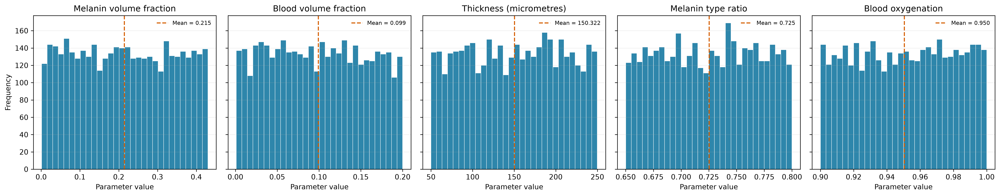

In [31]:
# Plot the distribution of each BioSkin property side by side
plot_param_names = param_names

fig, axes = plt.subplots(
    1,
    len(plot_param_names),
    figsize=(20, 4),
    sharey=True,
    dpi=300,
)

for ax, parameter in zip(axes, plot_param_names):
    values = bioskin_params_df[parameter]
    ax.hist(
        values,
        bins=30,
        color="#2E86AB",
        edgecolor="white",
        linewidth=0.5,
    )
    ax.axvline(
        values.mean(),
        color="#D55E00",
        linestyle="--",
        linewidth=1.5,
        label=f"Mean = {values.mean():.3f}",
    )
    ax.set_title(parameter)
    ax.set_xlabel("Parameter value")
    ax.grid(axis="y", alpha=0.2)
    ax.legend(frameon=False, fontsize=8)

axes[0].set_ylabel("Frequency")
"""
fig.suptitle(
    f"Distribution of BioSkin Skin Properties (n = {bioskin_params.shape[0]:,})",
    fontsize=14,
    y=1.03,
)
"""
plt.tight_layout()
plt.savefig('../figures/bioskin_properties_distribution.png', bbox_inches='tight')
plt.show()

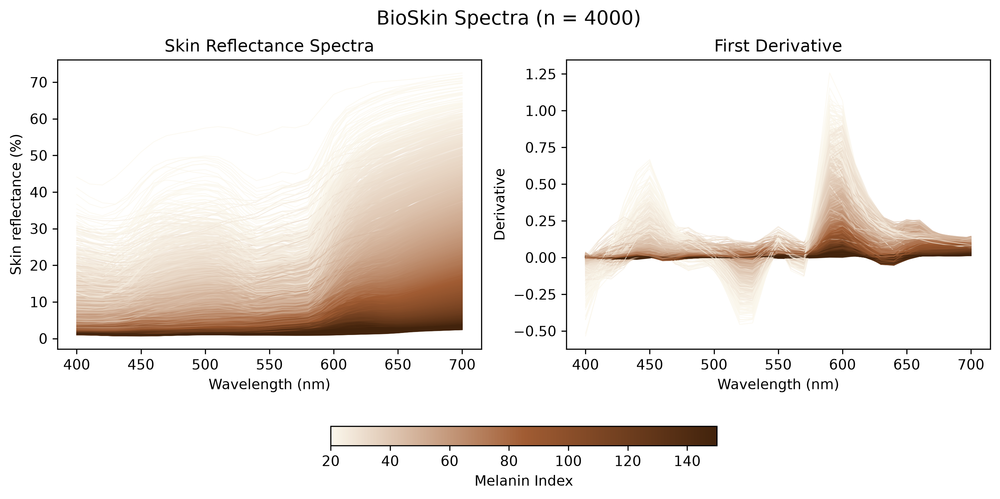

In [32]:
# Visualize the BioSkin spectra in the same format as the ISSA spectra
bioskin_drv = (
    savgol_filter(bioskin_spectra, window_length=5, polyorder=3, axis=1, deriv=1)
    / np.gradient(issa_wavelengths)
)
bioskin_mi = 100 * np.log10(100 / bioskin_spectra[:, -3])  # R at 680 nm
bioskin_mi_clipped = np.clip(bioskin_mi, 20, 150)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=300)

# Plot BioSkin spectra
ax = axes[0]
for i in range(bioskin_spectra.shape[0]):
    color = cmap(norm(bioskin_mi_clipped[i]))
    ax.plot(issa_wavelengths, bioskin_spectra[i, :], color=color, alpha=0.7, linewidth=0.6)
ax.set_title('Skin Reflectance Spectra')
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('Skin reflectance (%)')

# Plot first derivatives
ax = axes[1]
for i in range(bioskin_drv.shape[0]):
    color = cmap(norm(bioskin_mi_clipped[i]))
    ax.plot(issa_wavelengths, bioskin_drv[i, :], color=color, alpha=0.7, linewidth=0.6)
ax.set_title('First Derivative')
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('Derivative')

# Add the shared melanin-index colorbar
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = fig.colorbar(
    sm,
    ax=axes,
    orientation="horizontal",
    fraction=0.05,
    pad=0.2,
)
cbar.set_label("Melanin Index")

fig.suptitle(f'BioSkin Spectra (n = {bioskin_spectra.shape[0]})', fontsize=14)
plt.show()

## PCA comparison of ISSA, BVCM predictions, and BioSkin spectra

To compare spectral variation on a common basis, we fit PCA to the real ISSA face spectra and project the BVCM population-level predictions and the BioSkin `bioskin_spectra` onto the resulting components. This reference-based approach keeps the axes directly comparable: overlap with the ISSA score distribution indicates that a dataset reproduces the dominant empirical modes of variation, whereas displacement or dispersion outside the ISSA 95% score ellipse identifies systematic differences. BioSkin reflectance is already converted to percentages when loaded, so all three inputs use the same scale.

In [33]:
from sklearn.decomposition import PCA

pca_inputs = {
    'Real ISSA face data': face_spectra_clean,
    'BVCM predicted reflectance': synthetic_pop_spectra,
    'BioSkin spectra': bioskin_spectra,
}

# Learn the empirical spectral basis from ISSA, then use it for all datasets.
pca_issa = PCA(n_components=2)
pca_scores = {
    'Real ISSA face data': pca_issa.fit_transform(face_spectra_clean),
}
for name, spectra in pca_inputs.items():
    if name != 'Real ISSA face data':
        pca_scores[name] = pca_issa.transform(spectra)

# Quantify location, spread, and coverage relative to the ISSA PC1-PC2 region.
issa_score_mean = pca_scores['Real ISSA face data'].mean(axis=0)
issa_score_cov = np.cov(pca_scores['Real ISSA face data'], rowvar=False)
issa_score_precision = np.linalg.pinv(issa_score_cov)
issa_95_cutoff = chi2.ppf(0.95, df=2)

pca_comparison_rows = []
pca_region_coverage = {}
for name, scores in pca_scores.items():
    centered_scores = scores - issa_score_mean
    squared_distance = np.einsum(
        'ij,jk,ik->i', centered_scores, issa_score_precision, centered_scores
    )
    centroid_offset = scores.mean(axis=0) - issa_score_mean
    centroid_distance = np.sqrt(centroid_offset @ issa_score_precision @ centroid_offset)
    coverage_percent = 100 * np.mean(squared_distance <= issa_95_cutoff)
    pca_region_coverage[name] = coverage_percent
    pca_comparison_rows.append({
        'Dataset': name,
        'n': scores.shape[0],
        'PC1 mean': scores[:, 0].mean(),
        'PC1 SD': scores[:, 0].std(ddof=1),
        'PC2 mean': scores[:, 1].mean(),
        'PC2 SD': scores[:, 1].std(ddof=1),
        'Centroid distance from ISSA': centroid_distance,
        'Within ISSA 95% region (%)': coverage_percent,
    })

pca_comparison = pd.DataFrame(pca_comparison_rows)
pca_comparison_formatted = pca_comparison.style.format({
    'PC1 mean': '{:.2f}', 'PC1 SD': '{:.2f}',
    'PC2 mean': '{:.2f}', 'PC2 SD': '{:.2f}',
    'Centroid distance from ISSA': '{:.2f}',
    'Within ISSA 95% region (%)': '{:.1f}',
})

In [34]:
# Visual comparison of the shared PCA scores.
fig, ax = plt.subplots(figsize=(8, 6), dpi=300)

# Colorblind-safe colors plus distinct markers make each source identifiable.
dataset_styles = {
    'Real ISSA face data': {'color': '#0072B2', 'marker': 'o', 's': 9, 'alpha': 0.25, 'zorder': 1},
    'BVCM predicted reflectance': {'color': '#D55E00', 'marker': '^', 's': 13, 'alpha': 0.50, 'zorder': 2},
    'BioSkin spectra': {'color': '#009E73', 'marker': 'x', 's': 16, 'alpha': 0.65, 'zorder': 4},
}

plot_order = ['Real ISSA face data', 'BVCM predicted reflectance', 'BioSkin spectra']
for name in plot_order:
    scores = pca_scores[name]
    style = dataset_styles[name]
    coverage_label = '' if name == 'Real ISSA face data' else f'; {pca_region_coverage[name]:.1f}% inside ISSA region'
    ax.scatter(
        scores[:, 0], scores[:, 1],
        color=style['color'], marker=style['marker'], s=style['s'],
        alpha=style['alpha'], zorder=style['zorder'], linewidths=0.7,
        label=f'{name} (n={scores.shape[0]:,}{coverage_label})', rasterized=True,
    )
    # Mark each dataset centroid with a large X in the same color.
    ax.scatter(
        scores[:, 0].mean(), scores[:, 1].mean(), marker='X', s=100,
        color=style['color'], edgecolor='white', linewidth=0.9, zorder=style['zorder'] + 4,
    )

draw_ellipse(
    issa_score_mean, issa_score_cov, level=0.95, ax=ax,
    edgecolor='#1A1A1A', linewidth=1.5, linestyle='--',
    label='ISSA 95% score region',
)
explained = 100 * pca_issa.explained_variance_ratio_
ax.set_xlabel(f'PC1 ({explained[0]:.1f}% of ISSA variance)')
ax.set_ylabel(f'PC2 ({explained[1]:.1f}% of ISSA variance)')
ax.set_title('Projection onto the ISSA PCA basis')
ax.axhline(0, color='0.85', linewidth=0.7, zorder=0)
ax.axvline(0, color='0.85', linewidth=0.7, zorder=0)
ax.legend(
    title='Dataset (color and marker)', loc='lower left',
    frameon=True, facecolor='white', framealpha=0.92,
    fontsize=8, title_fontsize=9, markerscale=2.2,
)

plt.tight_layout()
plt.savefig('../figures/pca_issa_bvcm_bioskin_comparison.png', bbox_inches='tight')
plt.close(fig)

In [35]:
from IPython.display import display

display(pca_comparison_formatted)
print(f"The first two ISSA components explain {100 * pca_issa.explained_variance_ratio_.sum():.2f}% of spectral variance.")
print(f"Corrected BioSkin spectra within the ISSA PC1-PC2 95% score ellipse: {pca_region_coverage['BioSkin spectra']:.2f}%.")
print('This PCA comparison is descriptive and is separate from the two-stage validation decision.')


,Dataset,n,PC1 mean,PC1 SD,PC2 mean,PC2 SD,Centroid distance from ISSA,Within ISSA 95% region (%)
0,Real ISSA face data,7923,0.00,41.01,0.00,8.42,0.00,93.4
1,BVCM predicted reflectance,3000,0.53,39.31,0.43,7.80,0.05,95.4
2,BioSkin spectra,4000,-107.53,51.16,-5.51,10.86,2.70,22.8


The first two ISSA components explain 98.55% of spectral variance.
Corrected BioSkin spectra within the ISSA PC1-PC2 95% score ellipse: 22.78%.
This PCA comparison is descriptive and is separate from the two-stage validation decision.


## Stage 1: Chromophore index validation

In [36]:
def plot_spectra_filtered(spectra_valid, mi_valid, spectra_invalid, mi_invalid, wavelengths, title):
    fitzpatrick = ["#fbf7ec", "#a15c33", "#42230c"]
    cmap = LinearSegmentedColormap.from_list("fitzpatrick", fitzpatrick)
    norm = plt.Normalize(vmin=20, vmax=150)
    valid_mi_clipped = np.clip(mi_valid, 20, 150)
    invalid_mi_clipped = np.clip(mi_invalid, 20, 150)

    fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=True, dpi=300)

    # Plot valid spectra
    ax = axes[0]
    for i in range(spectra_valid.shape[0]):
        color = cmap(norm(valid_mi_clipped[i]))
        ax.plot(wavelengths, spectra_valid[i, :], color=color, alpha=0.7, linewidth=0.6)
    ax.set_title(f'Valid (n = {spectra_valid.shape[0]})')
    ax.set_xlabel('Wavelength (nm)')
    ax.set_ylabel('Skin reflectance (%)')
    # Plot invalid spectra
    ax = axes[1]
    for i in range(spectra_invalid.shape[0]):
        color = cmap(norm(invalid_mi_clipped[i]))
        ax.plot(wavelengths, spectra_invalid[i, :], color=color, alpha=0.7, linewidth=0.6)
    ax.set_title(f'Invalid (n = {spectra_invalid.shape[0]})')
    ax.set_xlabel('Wavelength (nm)')
    
    # -------- Colorbar --------
    sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])

    cbar = fig.colorbar(
        sm,
        ax=axes.ravel().tolist(),
        orientation="horizontal",
        fraction=0.05,     # thickness
        pad=0.2            # distance from plots
    )
    cbar.set_label("Melanin Index")

    # ---- Common title ----
    fig.suptitle(title, fontsize=14, y=1.02)
    plt.show()

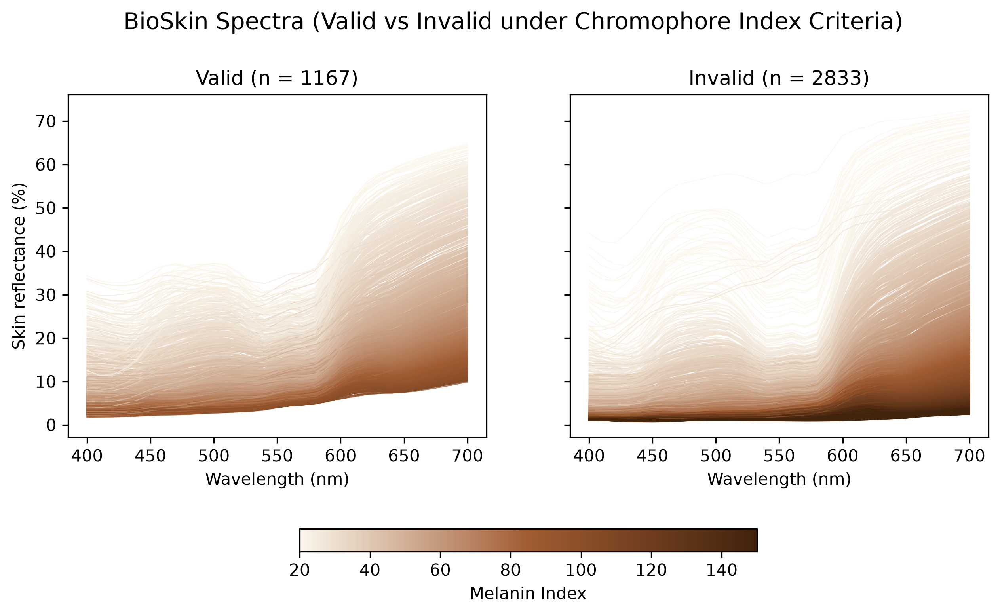

In [37]:
# Chromophore Index Validation
bioskin_mi = 100 * np.log10(100 / bioskin_spectra[:, 28])
bioskin_ei = 100 * np.log10(bioskin_spectra[:, 28] / bioskin_spectra[:, 16])
bioskin_cov = np.vstack([bioskin_mi, bioskin_ei]).transpose()

level = 0.95
# print(f"\nFiltering BioSkin spectra using Chromophore Index Criteria at {level*100:.1f}% confidence level")
valid_chr_indices = mahalanobis_distance(bioskin_cov, gmm).min(axis=1) <= np.sqrt(chi2.ppf(level, 2))
# Split the BioSkin spectra and melanin index into valid and invalid sets
bioskin_chr_valid = bioskin_spectra[valid_chr_indices, :]
bioskin_chr_invalid = bioskin_spectra[~valid_chr_indices, :]
bioskin_mi_chr_valid = bioskin_mi[valid_chr_indices]
bioskin_mi_chr_invalid = bioskin_mi[~valid_chr_indices]
bioskin_ei_chr_valid = bioskin_ei[valid_chr_indices]
bioskin_ei_chr_invalid = bioskin_ei[~valid_chr_indices]
bioskin_cov_chr_valid = bioskin_cov[valid_chr_indices, :]
bioskin_cov_chr_invalid = bioskin_cov[~valid_chr_indices, :]

plot_spectra_filtered(bioskin_chr_valid, bioskin_mi_chr_valid, bioskin_chr_invalid, bioskin_mi_chr_invalid, issa_wavelengths, title="BioSkin Spectra (Valid vs Invalid under Chromophore Index Criteria)")

## Stage 2: Spectral plausibility assessment

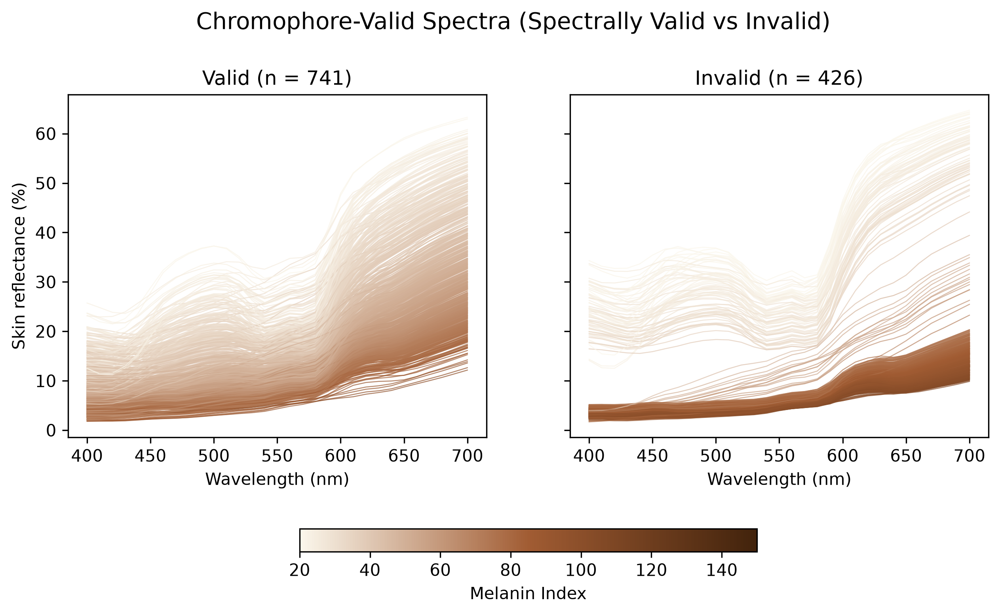

In [38]:
# Spectral Plausibility Assessment
# Apply this filter only to spectra that passed Stage 1
# The reference is the BVCM refitted to all cleaned ISSA facial spectra

# 1. Compute population-level predictions for valid spectra
bioskin_chr_valid_X = np.column_stack((np.ones(bioskin_chr_valid.shape[0]), bioskin_cov_chr_valid))  # Shape: (N_valid, 3)
bioskin_chr_valid_predictions = bioskin_chr_valid_X @ ref_betas_mean  # Shape: (N_valid, M_wavelengths)

# 2. Transform candidate spectra to logit space
bioskin_chr_valid_logit = logit(bioskin_chr_valid / 100)

# 3. Calculate Mahalanobis distances
# Use the learned covariance structure from random effects and noise
# Combined covariance: K_z (random effects) + diag(sigma_t^2) (observation noise)
ref_prior_var = ref_eta_z**2 * spectral_density_matern(bvcm_full.omega, ref_ls_z)
K_z = bvcm_full.Phi @ np.diag(ref_prior_var) @ bvcm_full.Phi.T
total_cov = K_z + ref_sigma2 * np.eye(K_z.shape[0])

# Compute the inverse covariance matrix (precision matrix)
try:
    total_cov_inv = np.linalg.inv(total_cov)
except np.linalg.LinAlgError:
    # If singular, use pseudo-inverse
    total_cov_inv = np.linalg.pinv(total_cov)

# Calculate Mahalanobis distance for each valid spectrum
residuals = bioskin_chr_valid_logit - bioskin_chr_valid_predictions
mahal_distances = np.sqrt(np.einsum('ij,jk,ik->i', residuals, total_cov_inv, residuals))

# 4. Determine threshold in-sample from all reference spectra
# Calculate Mahalanobis distances for the ISSA spectra used to fit the reference
reference_residuals = logit_face_spectra - X @ ref_betas_mean
reference_mahal_distances = np.sqrt(np.einsum('ij,jk,ik->i', reference_residuals, total_cov_inv, reference_residuals))

# Use 95th percentile as threshold
threshold_percentile = 95
mahal_threshold = np.percentile(reference_mahal_distances, threshold_percentile)

# print(f"\nSpectral Plausibility Assessment:")
# print(f"Mahalanobis distance threshold ({threshold_percentile}th percentile): {mahal_threshold:.2f}")
# print(f"Reference distance range: [{reference_mahal_distances.min():.2f}, {reference_mahal_distances.max():.2f}]")
# print(f"Valid spectra distance range: [{mahal_distances.min():.2f}, {mahal_distances.max():.2f}]")

# 5. Filter based on Mahalanobis distance
valid_spec_indices = mahal_distances <= mahal_threshold

# Split into spectrally valid and invalid
bioskin_spec_valid = bioskin_chr_valid[valid_spec_indices, :]
bioskin_spec_invalid = bioskin_chr_valid[~valid_spec_indices, :]
bioskin_mi_spec_valid = bioskin_mi_chr_valid[valid_spec_indices]
bioskin_mi_spec_invalid = bioskin_mi_chr_valid[~valid_spec_indices]
bioskin_ei_spec_valid = bioskin_ei_chr_valid[valid_spec_indices]
bioskin_ei_spec_invalid = bioskin_ei_chr_valid[~valid_spec_indices]

# print(f"\nResults:")
# print(f"Passed Stage 1 (Chromophore): {bioskin_chr_valid.shape[0]} / {bioskin_spectra.shape[0]} ({100*bioskin_chr_valid.shape[0]/bioskin_spectra.shape[0]:.1f}%)")
# print(f"Passed Stage 2 (Spectral): {bioskin_spec_valid.shape[0]} / {bioskin_chr_valid.shape[0]} ({100*bioskin_spec_valid.shape[0]/bioskin_chr_valid.shape[0]:.1f}%)")
# print(f"Total Valid Spectra: {bioskin_spec_valid.shape[0]} / {bioskin_spectra.shape[0]} ({100*bioskin_spec_valid.shape[0]/bioskin_spectra.shape[0]:.1f}%)")

plot_spectra_filtered(bioskin_spec_valid, bioskin_mi_spec_valid, bioskin_spec_invalid, bioskin_mi_spec_invalid, 
                      issa_wavelengths, title="Chromophore-Valid Spectra (Spectrally Valid vs Invalid)")

## BioSkin spectra validation overview

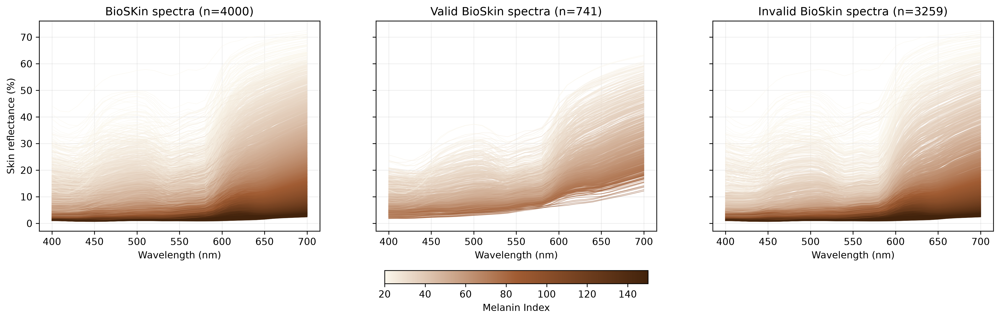

In [39]:
# Three-panel overview: all BioSkin spectra, final valid spectra, and final invalid spectra
final_valid_indices = np.zeros(bioskin_spectra.shape[0], dtype=bool)
chromophore_valid_positions = np.where(valid_chr_indices)[0]
final_valid_indices[chromophore_valid_positions[valid_spec_indices]] = True

bioskin_valid = bioskin_spectra[final_valid_indices, :]
bioskin_invalid = bioskin_spectra[~final_valid_indices, :]
bioskin_mi_valid = bioskin_mi[final_valid_indices]
bioskin_mi_invalid = bioskin_mi[~final_valid_indices]

plot_sets = [
    (bioskin_spectra, bioskin_mi, f"BioSKin spectra (n={bioskin_spectra.shape[0]})"),
    (bioskin_valid, bioskin_mi_valid, f"Valid BioSkin spectra (n={bioskin_valid.shape[0]})"),
    (bioskin_invalid, bioskin_mi_invalid, f"Invalid BioSkin spectra (n={bioskin_invalid.shape[0]})"),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True, dpi=300)

for ax, (spectra, mi_values, title) in zip(axes, plot_sets):
    mi_clipped = np.clip(mi_values, 20, 150)
    for i in range(spectra.shape[0]):
        color = cmap(norm(mi_clipped[i]))
        ax.plot(issa_wavelengths, spectra[i, :], color=color, alpha=0.55, linewidth=0.6)
    ax.set_title(title)
    ax.set_xlabel("Wavelength (nm)")
    ax.grid(alpha=0.2)

axes[0].set_ylabel("Skin reflectance (%)")

sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes.ravel().tolist(), orientation="horizontal", fraction=0.05, pad=0.15)
cbar.set_label("Melanin Index")

# fig.suptitle("BioSkin Spectra Validation Overview", fontsize=14, y=1.02)
plt.savefig("../figures/bioskin_spectra_validation_overview.png", bbox_inches='tight')
plt.show()

## Validation results summary

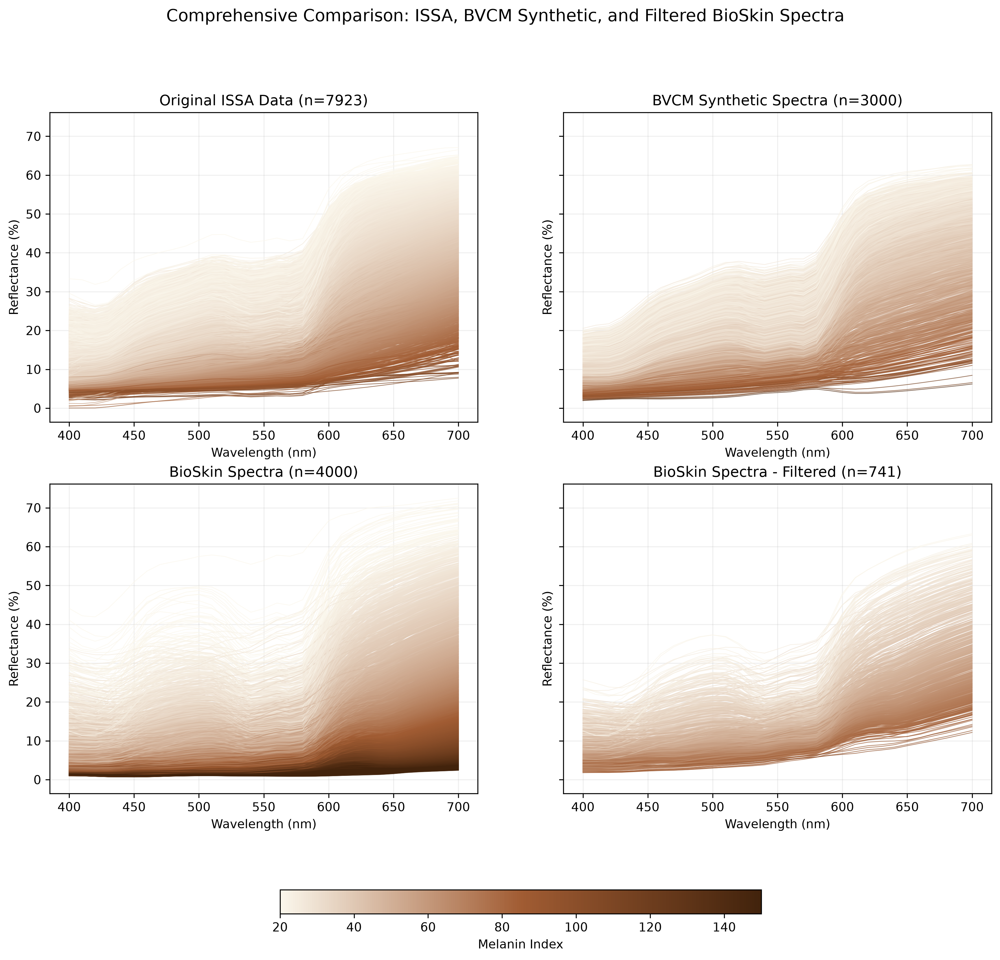

In [40]:
# Comprehensive visualization: original data, synthetic data, and filtered BioSkin spectra
fig, axes = plt.subplots(2, 2, figsize=(14, 12), sharey=True, dpi=300)

# Prepare colormaps
valid_mi_clipped = np.clip(bioskin_mi_spec_valid, 20, 150)
sampled_mi_clipped_plot = np.clip(sampled_mi, 20, 150)

# Plot 1: Original ISSA data
ax = axes[0, 0]
for i in range(face_spectra_clean.shape[0]):
    color = cmap(norm(face_mi_clipped[i]))
    ax.plot(issa_wavelengths, face_spectra_clean[i, :], color=color, alpha=0.7, linewidth=0.6)
ax.set_title(f'Original ISSA Data (n={face_spectra_clean.shape[0]})')
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('Reflectance (%)')
# ax.set_ylim([0, 100])
ax.grid(alpha=0.2)

# Plot 2: BVCM-generated synthetic spectra
ax = axes[0, 1]
for i in range(num_samples):
    color = cmap(norm(sampled_mi_clipped_plot[i]))
    ax.plot(issa_wavelengths, synthetic_pop_spectra[i, :], color=color, alpha=0.7, linewidth=0.6)
ax.set_title(f'BVCM Synthetic Spectra (n={num_samples})')
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('Reflectance (%)')
# ax.set_ylim([0, 100])
ax.grid(alpha=0.2)

# Plot 3: BioSkin spectra (all)
ax = axes[1, 0]
bioskin_mi_clipped_all = np.clip(bioskin_mi, 20, 150)
for i in range(bioskin_spectra.shape[0]):
    color = cmap(norm(bioskin_mi_clipped_all[i]))
    ax.plot(issa_wavelengths, bioskin_spectra[i, :], color=color, alpha=0.7, linewidth=0.6)
ax.set_title(f'BioSkin Spectra (n={bioskin_spectra.shape[0]})')
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('Reflectance (%)')
# ax.set_ylim([0, 100])
ax.grid(alpha=0.2)

# Plot 4: BioSkin spectra (filtered - valid only)
ax = axes[1, 1]
for i in range(bioskin_spec_valid.shape[0]):
    color = cmap(norm(valid_mi_clipped[i]))
    ax.plot(issa_wavelengths, bioskin_spec_valid[i, :], color=color, alpha=0.7, linewidth=0.6)
ax.set_title(f'BioSkin Spectra - Filtered (n={bioskin_spec_valid.shape[0]})')
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('Reflectance (%)')
# ax.set_ylim([0, 100])
ax.grid(alpha=0.2)

# Add shared colorbar
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes.ravel().tolist(), orientation="horizontal", 
                    fraction=0.03, pad=0.12)
cbar.set_label("Melanin Index")

plt.suptitle('Comprehensive Comparison: ISSA, BVCM Synthetic, and Filtered BioSkin Spectra', 
             fontsize=14)

plt.show()

In [41]:
# Summary statistics and validation metrics
print("\n" + "="*70)
print("TWO-STAGE VALIDATION FILTER SUMMARY")
print("="*70)

print(f"\nStage 1: Chromophore Index Validation (GMM 95% CI)")
print(f"  Input spectra: {bioskin_spectra.shape[0]}")
print(f"  Valid (within GMM): {bioskin_chr_valid.shape[0]} ({100*bioskin_chr_valid.shape[0]/bioskin_spectra.shape[0]:.1f}%)")
print(f"  Invalid (outside GMM): {bioskin_chr_invalid.shape[0]} ({100*bioskin_chr_invalid.shape[0]/bioskin_spectra.shape[0]:.1f}%)")

print(f"\nStage 2: Spectral Plausibility Assessment (Mahalanobis Distance)")
print(f"  Input (from Stage 1): {bioskin_chr_valid.shape[0]}")
print(f"  Threshold: {mahal_threshold:.2f} (in-sample 95th percentile, all ISSA facial spectra)")
print(f"  Valid (plausible spectra): {bioskin_spec_valid.shape[0]} ({100*bioskin_spec_valid.shape[0]/bioskin_chr_valid.shape[0]:.1f}%)")
print(f"  Invalid (implausible spectra): {bioskin_spec_invalid.shape[0]} ({100*bioskin_spec_invalid.shape[0]/bioskin_chr_valid.shape[0]:.1f}%)")

print(f"\nOverall Filter Performance:")
print(f"  Total input: {bioskin_spectra.shape[0]}")
print(f"  Total valid: {bioskin_spec_valid.shape[0]} ({100*bioskin_spec_valid.shape[0]/bioskin_spectra.shape[0]:.1f}%)")
print(f"  Total rejected: {bioskin_spectra.shape[0] - bioskin_spec_valid.shape[0]} ({100*(bioskin_spectra.shape[0] - bioskin_spec_valid.shape[0])/bioskin_spectra.shape[0]:.1f}%)")

print(f"\nChromophore Index Statistics (Valid Spectra):")
print(f"  Melanin Index: [{bioskin_mi_spec_valid.min():.2f}, {bioskin_mi_spec_valid.max():.2f}]")
print(f"  Erythema Index: [{bioskin_ei_spec_valid.min():.2f}, {bioskin_ei_spec_valid.max():.2f}]")

print("="*70)


TWO-STAGE VALIDATION FILTER SUMMARY

Stage 1: Chromophore Index Validation (GMM 95% CI)
  Input spectra: 4000
  Valid (within GMM): 1167 (29.2%)
  Invalid (outside GMM): 2833 (70.8%)

Stage 2: Spectral Plausibility Assessment (Mahalanobis Distance)
  Input (from Stage 1): 1167
  Threshold: 9.35 (in-sample 95th percentile, all ISSA facial spectra)
  Valid (plausible spectra): 741 (63.5%)
  Invalid (implausible spectra): 426 (36.5%)

Overall Filter Performance:
  Total input: 4000
  Total valid: 741 (18.5%)
  Total rejected: 3259 (81.5%)

Chromophore Index Statistics (Valid Spectra):
  Melanin Index: [20.85, 97.15]
  Erythema Index: [16.79, 49.53]


In [42]:
# Save reproducible results, preserving original CSV row order for later analysis.
import hashlib
import json
import platform
from datetime import datetime, timezone
from importlib.metadata import version

validation_dir = project_root / 'output' / 'corrected_validation'
validation_dir.mkdir(parents=True, exist_ok=True)
n_candidates = len(bioskin_spectra)
stage2_distances_all = np.full(n_candidates, np.nan)
stage2_distances_all[valid_chr_indices] = mahal_distances
stage2_pass_all = pd.array([pd.NA] * n_candidates, dtype='boolean')
stage2_pass_all[valid_chr_indices] = valid_spec_indices

validation_results = bioskin_physical_params.copy()
validation_results.insert(0, 'sample_id', np.arange(1, n_candidates + 1))
validation_results['MI'] = bioskin_mi
validation_results['EI'] = bioskin_ei
validation_results['stage1_min_mahalanobis'] = mahalanobis_distance(bioskin_cov, gmm).min(axis=1)
validation_results['stage1_pass'] = valid_chr_indices
validation_results['stage2_evaluated'] = valid_chr_indices
validation_results['stage2_mahalanobis'] = stage2_distances_all
validation_results['stage2_pass'] = stage2_pass_all
validation_results['final_pass'] = final_valid_indices
validation_results['outcome'] = np.where(
    ~valid_chr_indices, 'rejected_stage_1',
    np.where(final_valid_indices, 'passed_both', 'rejected_stage_2'),
)
validation_results.to_csv(validation_dir / 'per_spectrum_results.csv', index=False)
param_summary.to_csv(validation_dir / 'physical_parameter_summary.csv')
pca_comparison.to_csv(validation_dir / 'pca_comparison.csv', index=False)

def index_range(values):
    return [float(values.min()), float(values.max())] if len(values) else None

validation_summary = {
    'status': 'complete',
    'fit_source': fit_source,
    'checkpoint_file': checkpoint_path.name,
    'checkpoint_sha256': hashlib.sha256(checkpoint_path.read_bytes()).hexdigest(),
    'sampler_sha256': sampler_sha256,
    'fit_acceptance_rate': fit_acceptance_rate,
    'posterior_mean_length_scale': float(ls_z),
    'posterior_mean_amplitude': float(eta_z),
    'posterior_mean_noise_variance': float(sigma2),
    'stage2_reference': 'BVCM refitted to all cleaned ISSA facial spectra',
    'stage2_reference_spectra': int(N),
    'stage2_reference_fit_source': full_fit_source,
    'stage2_reference_checkpoint_file': full_checkpoint_path.name,
    'stage2_reference_checkpoint_sha256': hashlib.sha256(full_checkpoint_path.read_bytes()).hexdigest(),
    'stage2_reference_fit_acceptance_rate': full_fit_acceptance_rate,
    'stage2_reference_posterior_mean_length_scale': float(ref_ls_z),
    'stage2_reference_posterior_mean_amplitude': float(ref_eta_z),
    'stage2_reference_posterior_mean_noise_variance': float(ref_sigma2),
    'stage2_threshold_calibration': 'in-sample 95th percentile over all reference spectra',
    'completed_at_utc': datetime.now(timezone.utc).isoformat(),
    'source_files': bioskin_input['source_files'],
    'issa_workbook_sha256': hashlib.sha256(issa_path.read_bytes()).hexdigest(),
    'wavelengths_nm': issa_wavelengths.tolist(),
    'reflectance_units_in_validation': 'percent',
    'issa_face_spectra': int(len(face_spectra_clean)),
    'training_spectra': int(len(train_indices)),
    'test_spectra': int(len(test_indices)),
    'candidate_spectra': n_candidates,
    'stage1_pass': int(valid_chr_indices.sum()),
    'stage1_rejected': int((~valid_chr_indices).sum()),
    'stage2_pass': int(valid_spec_indices.sum()),
    'stage2_rejected': int((~valid_spec_indices).sum()),
    'passed_both': int(final_valid_indices.sum()),
    'rejected_overall': int((~final_valid_indices).sum()),
    'passed_both_percent': float(100 * final_valid_indices.mean()),
    'stage1_threshold': float(np.sqrt(chi2.ppf(0.95, 2))),
    'stage2_threshold': float(mahal_threshold),
    'retained_MI_range': index_range(bioskin_mi_spec_valid),
    'retained_EI_range': index_range(bioskin_ei_spec_valid),
    'bioskin_pca_coverage_percent': float(pca_region_coverage['BioSkin spectra']),
    'python_version': platform.python_version(),
    'package_versions': {name: version(name) for name in ['numpy', 'pandas', 'scipy', 'scikit-learn', 'patsy']},
}
(validation_dir / 'summary.json').write_text(json.dumps(validation_summary, indent=2), encoding='utf-8')

# Compact reference state supports future validation without another MCMC fit.
np.savez_compressed(
    validation_dir / 'reference_state.npz',
    wavelengths=issa_wavelengths, post_betas_mean=ref_betas_mean,
    evaluation_post_betas_mean=post_betas_mean,
    total_cov=total_cov, mahal_threshold=mahal_threshold,
    gmm_weights=gmm.weights_, gmm_means=gmm.means_,
    gmm_covariances=gmm.covariances_,
    train_indices=train_indices, test_indices=test_indices,
    pca_components=pca_issa.components_, pca_mean=pca_issa.mean_,
    pca_score_mean=issa_score_mean, pca_score_cov=issa_score_cov,
)
print(f'Validation results saved to {validation_dir}')


Validation results saved to F:\SeaFiles\Seafile\SkinSpectra\SkinSim_Quarto\output\corrected_validation
